# PromptPiper — Visualizations

Organized by research question (see §Objectives in the paper):

1. **RQ1** — Trade-off between prompt compression and task performance
2. **RQ2** — How PromptPiper compares to existing baselines
3. **RQ3** — Cost and convergence characteristics
4. **RQ4** — Patterns in compression strategies and transferability

Missing results are skipped gracefully — re-run when new experiments complete.

In [1]:
import json
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

RESULTS_DIR = Path('../results/icse_26')

# ── Figure size constants (IEEE two-column format, inches) ────────────────────
COL1  = 6.3    # single-column width
COL2  = 13   # full text-width (double column)
ROW_H = 2.5    # height per subplot row

FIG_DIR = Path('../paper/prompt_piper_paper/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
# ─────────────────────────────────────────────────────────────────────────────

# Models — display name, directory name, access type
MODELS = [
    ('GPT-5.4-nano',         'gpt-5.4-nano-2026-03-17',     'remote'),
    ('Gemini-3-Flash',       'gemini-3-flash-preview',      'remote'),
    ('Gemma-4-26B',          'gemma-4-26b-a4b-it',          'local'),
    ('Qwen3.5-9B',           'qwen3.5-9b',                  'local'),
]

# All tasks — (run_name_stem, display_label, local_only)
TASKS = [
    ('mbpp_instruct_nsga2',         'MBPP',        False),
    ('mmlu_pro_cs_nsga2',           'MMLU-Pro CS', False),
    ('gsm8k_cot_nsga2',             'GSM8K',       False),
    ('bbh_logical_deduction_nsga2', 'BBH-Logic',   False),
    ('musr_murder_mysteries_nsga2', 'MuSR',        True),
]
COMMON_TASKS  = [(s, l, lo) for s, l, lo in TASKS if not lo]
LOCAL_TASKS   = [(s, l, lo) for s, l, lo in TASKS if lo]

TRANSFER_PAIRS = [
    ('gsm8k_cot_nsga2',             'bbh_logical_deduction_nsga2'),
    ('bbh_logical_deduction_nsga2', 'gsm8k_cot_nsga2'),
]

BASELINE_STYLE = {
    'no_compression':      {'color': '#555555', 'marker': 'D', 'label': 'No compression'},
    'all_transformations': {'color': '#e06c75', 'marker': 's', 'label': 'All transforms'},
    'random_search':       {'color': '#d19a66', 'marker': '^', 'label': 'Random search'},
    'multi_armed_bandit':  {'color': '#e5c07b', 'marker': '*', 'label': 'MAB'},
    'summarization':       {'color': '#c678dd', 'marker': 'P', 'label': 'Summarization'},
    'truncated_prompt':    {'color': '#61afef', 'marker': 'v', 'label': 'Truncated'},
    'random_deletion':     {'color': '#56b6c2', 'marker': 'X', 'label': 'Rand. deletion'},
    'llmlingua2':          {'color': '#98c379', 'marker': 'h', 'label': 'LLMLingua-2'},
}

NSGA2_COLOR   = '#2196F3'
SEARCH_COLOR  = '#90CAF9'

MODEL_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3']

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

# ── Loaders ───────────────────────────────────────────────────────────────────

def load_json(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None

def load_jsonl(path):
    try:
        with open(path) as f:
            return [json.loads(l) for l in f]
    except Exception:
        return None

def all_results():
    """Return nested dict: results[model_dir][run_stem] = data."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        mpath = RESULTS_DIR / mdir
        if not mpath.exists():
            continue
        for stem, _, _ in TASKS:
            d = load_json(mpath / f'{stem}.json')
            if d:
                out[mdir][stem] = d
        for src, tgt in TRANSFER_PAIRS:
            d = load_json(mpath / f'transfer_{src}_to_{tgt}.json')
            if d:
                out[mdir][f'transfer_{src}_to_{tgt}'] = d
    return out

def all_detailed():
    """Return nested dict: detailed[model_dir][run_stem] = list of row dicts."""
    out = {}
    for _, mdir, _ in MODELS:
        out[mdir] = {}
        det_path = RESULTS_DIR / mdir / 'detailed'
        if not det_path.exists():
            continue
        for stem, _, _ in TASKS:
            rows = load_jsonl(det_path / f'{stem}_detailed.jsonl')
            if rows:
                out[mdir][stem] = rows
        for src, tgt in TRANSFER_PAIRS:
            key = f'transfer_{src}_to_{tgt}'
            rows = load_jsonl(det_path / f'{key}_detailed.jsonl')
            if rows:
                out[mdir][key] = rows
    return out

RESULTS  = all_results()
DETAILED = all_detailed()

print('Results loaded:')
for mlabel, mdir, _ in MODELS:
    runs = list(RESULTS[mdir].keys())
    det  = list(DETAILED[mdir].keys())
    print(f'  {mlabel}: {len(runs)} runs, {len(det)} detailed')

Results loaded:
  GPT-5.4-nano: 6 runs, 6 detailed
  Gemini-3-Flash: 6 runs, 6 detailed
  Gemma-4-26B: 7 runs, 6 detailed
  Qwen3.5-9B: 6 runs, 6 detailed


---
## RQ1 — Trade-off between Prompt Compression and Task Performance

> *What is the trade-off between prompt compression and task performance?*

Each subplot shows the NSGA-II Pareto front (search set in light blue, test set in dark blue) and all baselines evaluated on the test set.

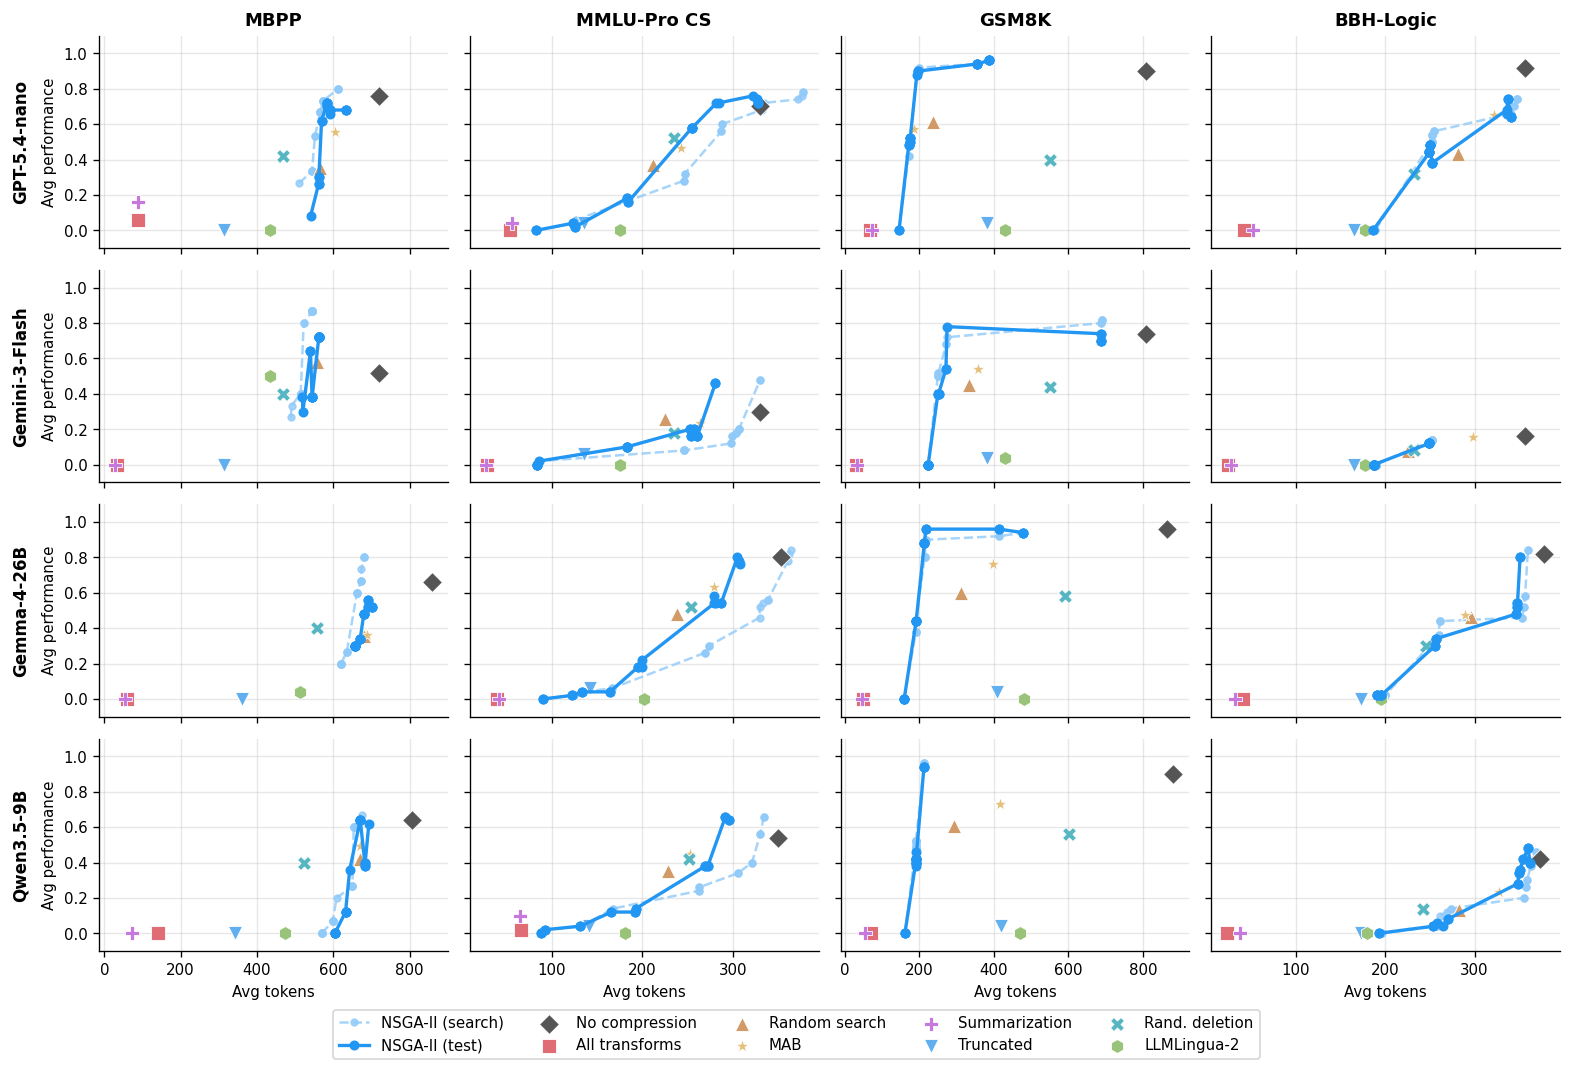

In [2]:
# Helper: extract (tokens, perf) for a list of solutions from JSON
def pareto_xy_json(solutions, split='test'):
    tok  = [s.get(f'{split}_avg_tokens')      or s['search_avg_tokens']      for s in solutions]
    perf = [s.get(f'{split}_avg_performance') or s['search_avg_performance'] for s in solutions]
    return np.array(tok), np.array(perf)

def draw_pareto_front(ax, tokens, perfs, color, label, lw=2, ms=5, ls='-'):
    order = np.argsort(tokens)
    ax.plot(tokens[order], perfs[order], f'o{ls}', color=color, lw=lw,
            markersize=ms, label=label, zorder=6)

def draw_baselines(ax, baselines, split='test'):
    for bl in baselines:
        bname = bl['name']
        if bname not in BASELINE_STYLE:
            continue
        st = BASELINE_STYLE[bname]
        bt = bl.get(f'{split}_avg_tokens')      or bl['search_avg_tokens']
        bp = bl.get(f'{split}_avg_performance') or bl['search_avg_performance']
        ax.scatter(bt, bp, s=80, label=st['label'],
                   color=st['color'], marker=st['marker'],
                   zorder=5, edgecolors='white', linewidths=0.5)


def rq1_grid(task_list, title_suffix='', filename=None):
    available_models = [(lbl, mdir) for lbl, mdir, _ in MODELS
                        if any(stem in RESULTS[mdir] for stem, _, _ in task_list)]
    available_tasks  = [(stem, lbl) for stem, lbl, _ in task_list
                        if any(stem in RESULTS[mdir] for _, mdir, _ in MODELS)]
    if not available_models or not available_tasks:
        print('No data available.')
        return

    nrows, ncols = len(available_models), len(available_tasks)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows * 0.85),
                             squeeze=False,
                             sharey='all', sharex='col')

    legend_handles = {}

    for ri, (mlabel, mdir) in enumerate(available_models):
        for ci, (stem, tlabel) in enumerate(available_tasks):
            ax = axes[ri][ci]
            ax.set_ylim(-0.1, 1.1)
            ax.set_xlabel('Avg tokens' if ri == nrows - 1 else '')
            ax.set_ylabel('Avg performance' if ci == 0 else '')
            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.25, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

            d = RESULTS[mdir].get(stem)
            if d is None:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                ax.set_visible(True)
                continue

            # Search pareto front
            stok, sperf = pareto_xy_json(d['pareto_solutions'], split='search')
            h, = ax.plot(*[x[np.argsort(stok)] for x in (stok, sperf)],
                         'o--', color=SEARCH_COLOR, lw=1.5, markersize=4,
                         label='NSGA-II (search)', zorder=5, alpha=0.8)
            legend_handles.setdefault('NSGA-II (search)', h)

            # Test pareto front
            ttok, tperf = pareto_xy_json(d['pareto_solutions'], split='test')
            h, = ax.plot(*[x[np.argsort(ttok)] for x in (ttok, tperf)],
                         'o-', color=NSGA2_COLOR, lw=2, markersize=5,
                         label='NSGA-II (test)', zorder=6)
            legend_handles.setdefault('NSGA-II (test)', h)

            # Baselines on test
            for bl in d['baselines']:
                bname = bl['name']
                if bname not in BASELINE_STYLE:
                    continue
                st = BASELINE_STYLE[bname]
                bt = bl.get('test_avg_tokens')       or bl['search_avg_tokens']
                bp = bl.get('test_avg_performance')  or bl['search_avg_performance']
                h = ax.scatter(bt, bp, s=70, color=st['color'], marker=st['marker'],
                               zorder=5, edgecolors='white', linewidths=0.5,
                               label=st['label'])
                legend_handles.setdefault(st['label'], h)

    handles = list(legend_handles.values())
    labels  = list(legend_handles.keys())
    fig.legend(handles, labels, loc='lower center',
               ncol=min(5, len(labels)),
               bbox_to_anchor=(0.5, -0.05), frameon=True, fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches='tight')
    plt.show()


rq1_grid(COMMON_TASKS, filename='rq1_common.pdf')

---
## RQ2 — How PromptPiper Compares to Existing Baselines

> *How does PromptPiper compare to existing baselines for prompt optimization?*

Distributions of per-example **performance** (left column) and **compressed tokens** (right column)
from the detailed results. Rows correspond to benchmarks. Each method's distribution is shown as a violin.

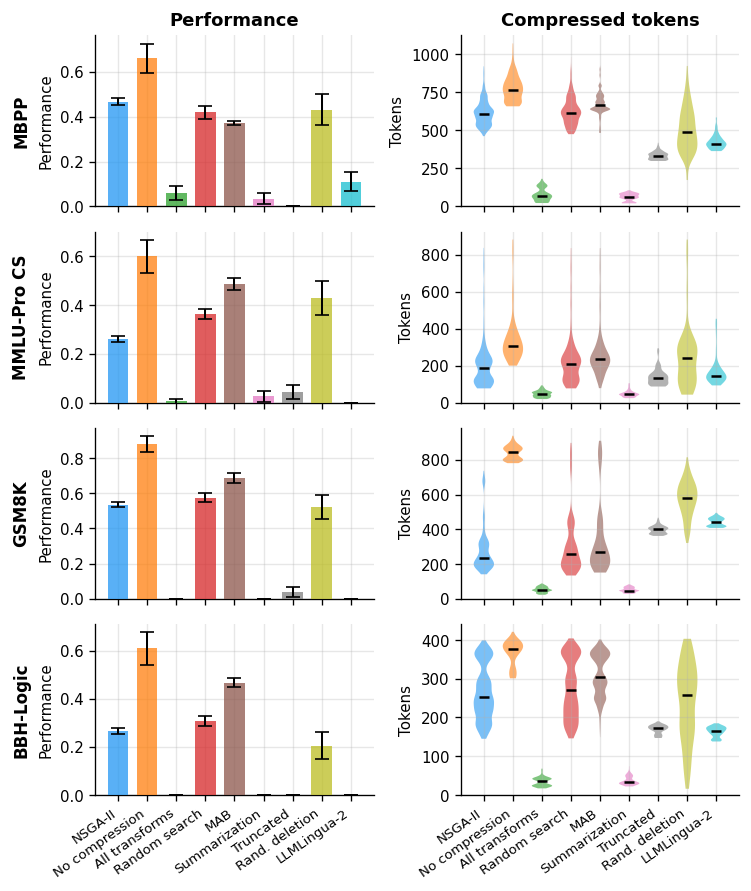

In [3]:
def collect_rq2_data():
    """Collect per-example perf & tokens from detailed results for all models × tasks."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            det = DETAILED[mdir].get(stem)
            if det is None:
                continue
            for row in det:
                sol_type = row['solution_type']
                if sol_type == 'pareto':
                    method = 'NSGA-II'
                elif sol_type.startswith('baseline_'):
                    bname = sol_type.replace('baseline_', '')
                    method = BASELINE_STYLE.get(bname, {}).get('label', bname)
                else:
                    continue
                rows.append({
                    'model': mlabel,
                    'task':  tlabel,
                    'method': method,
                    'performance': row['performance'],
                    'compressed_tokens': row['compressed_tokens'],
                })
    return pd.DataFrame(rows)


df_rq2 = collect_rq2_data()

if df_rq2.empty:
    print('No detailed results available for RQ2 plots.')
else:
    tasks_with_data  = [l for _, l, _ in TASKS if l in df_rq2['task'].unique()]
    methods_ordered  = (['NSGA-II']
                        + [st['label'] for st in BASELINE_STYLE.values()
                           if st['label'] in df_rq2['method'].unique()])
    methods_ordered  = list(dict.fromkeys(methods_ordered))

    method_colors = {m: c for m, c in zip(
        methods_ordered,
        plt.cm.tab10(np.linspace(0, 1, len(methods_ordered))))}
    method_colors['NSGA-II'] = NSGA2_COLOR

    nrows = len(tasks_with_data)
    ncols = 2  # performance bar | tokens violin

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL1, ROW_H * nrows * 0.75), sharex='col', squeeze=False)

    for ri, tlabel in enumerate(tasks_with_data):
        sub = df_rq2[df_rq2['task'] == tlabel]

        for ci, (metric, xlabel) in enumerate([
                ('performance', 'Performance'), ('compressed_tokens', 'Compressed tokens')]):
            ax = axes[ri][ci]
            positions = list(range(len(methods_ordered)))
            data_per_method = [sub[sub['method'] == m][metric].dropna().values
                               for m in methods_ordered]

            if ci == 0:
                # Bar chart with 95% CI for performance
                for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                    color = method_colors[m]
                    if len(data) == 0:
                        continue
                    mean_val = np.mean(data)
                    ci_val = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data)) if len(data) > 1 else 0
                    ax.bar(pos, mean_val, width=0.7, color=color, alpha=0.75, zorder=3)
                    ax.errorbar(pos, mean_val, yerr=ci_val, fmt='none',
                                color='black', capsize=4, linewidth=1.2, zorder=4)
                ax.set_ylim(bottom=0)
            else:
                # Violin for token distribution
                for pos, (m, data) in enumerate(zip(methods_ordered, data_per_method)):
                    if len(data) == 0:
                        continue
                    color = method_colors[m]
                    parts = ax.violinplot([data], positions=[pos], widths=0.7,
                                          showmedians=True, showextrema=False)
                    for pc in parts['bodies']:
                        pc.set_facecolor(color)
                        pc.set_alpha(0.6)
                    parts['cmedians'].set_color('black')
                    parts['cmedians'].set_linewidth(1.5)

            ax.set_xticks(positions)
            ax.set_xticklabels(methods_ordered, rotation=35, ha='right', fontsize=8)
            ax.set_ylabel(xlabel if ci == 0 else 'Tokens')
            if ci == 1:
                ax.set_ylim([0, None])
            if ri == 0:
                ax.set_title(xlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(tlabel, xy=(-0.3, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq2_distributions.pdf', bbox_inches='tight')
    plt.show()

### RQ2 (variant) — Best Pareto solution only

Same layout as above, but NSGA-II is represented by **a single solution per (model, task)**: the Pareto-front point closest to the ideal point (task performance = 1, normalised token count = 0), using Euclidean distance in that 2-D space. All baselines are unchanged.

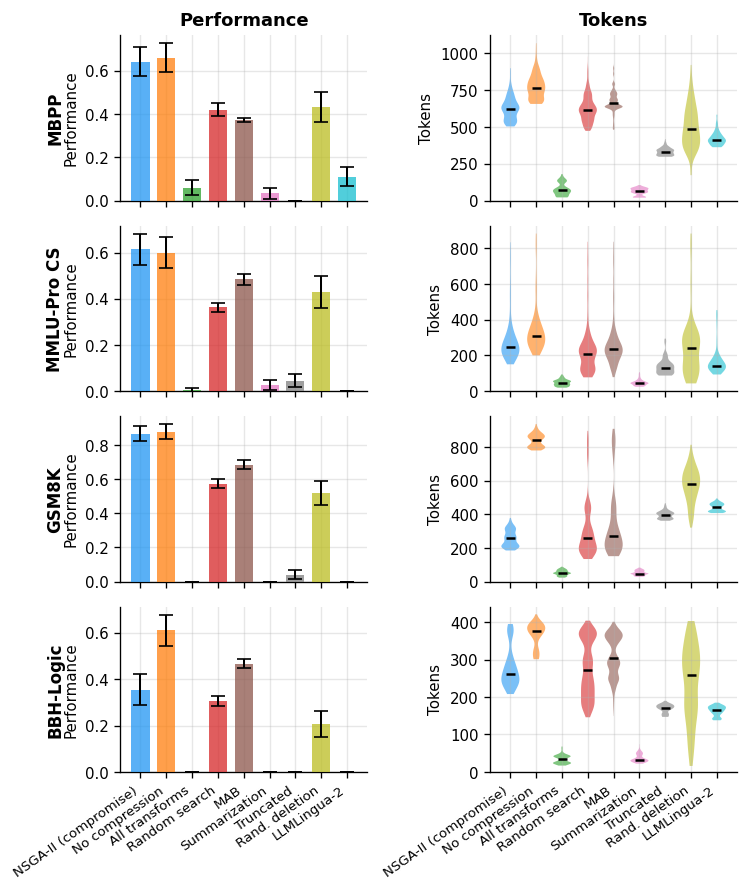

In [4]:
def find_best_pareto_id(pareto_solutions, ref_tokens):
    """Return the index (= solution_id) of the Pareto solution closest to (perf=1, norm_tok=0)."""
    best_id, best_dist = None, float('inf')
    ref_tokens = max(ref_tokens, 1)
    for i, sol in enumerate(pareto_solutions):
        perf = sol.get('test_avg_performance') or sol['search_avg_performance']
        tok  = sol.get('test_avg_tokens')      or sol['search_avg_tokens']
        dist = np.sqrt((1 - perf) ** 2 + (tok / ref_tokens) ** 2)
        if dist < best_dist:
            best_dist, best_id = dist, i
    return best_id


def collect_rq2_best_data():
    """Per-example perf & tokens: NSGA-II = best Pareto solution only; baselines unchanged."""
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            d   = RESULTS[mdir].get(stem)
            det = DETAILED[mdir].get(stem)
            if d is None or det is None:
                continue

            nc        = next((b for b in d['baselines'] if b['name'] == 'no_compression'), None)
            ref_toks  = (nc.get('test_avg_tokens') or nc['search_avg_tokens']) if nc else 1.0
            best_id   = find_best_pareto_id(d['pareto_solutions'], ref_toks)

            for row in det:
                sol_type = row['solution_type']
                if sol_type == 'pareto':
                    if row.get('solution_id') != best_id:
                        continue
                    method = 'NSGA-II (compromise)'
                elif sol_type.startswith('baseline_'):
                    bname  = sol_type.replace('baseline_', '')
                    method = BASELINE_STYLE.get(bname, {}).get('label', bname)
                else:
                    continue
                rows.append({
                    'model':             mlabel,
                    'task':              tlabel,
                    'method':            method,
                    'performance':       row['performance'],
                    'compressed_tokens': row['compressed_tokens'],
                })
    return pd.DataFrame(rows)


df_rq2_best = collect_rq2_best_data()

if df_rq2_best.empty:
    print('No detailed results available.')
else:
    tasks_with_data_best = [l for _, l, _ in TASKS if l in df_rq2_best['task'].unique()]
    methods_best = (['NSGA-II (compromise)']
                    + [st['label'] for st in BASELINE_STYLE.values()
                       if st['label'] in df_rq2_best['method'].unique()])
    methods_best = list(dict.fromkeys(methods_best))

    method_colors_best = {m: c for m, c in zip(
        methods_best, plt.cm.tab10(np.linspace(0, 1, len(methods_best))))}
    method_colors_best['NSGA-II (compromise)'] = NSGA2_COLOR

    nrows = len(tasks_with_data_best)
    fig, axes = plt.subplots(nrows, 2,
                             figsize=(COL1, ROW_H * nrows * 0.75),
                             sharex='col', squeeze=False)

    for ri, tlabel in enumerate(tasks_with_data_best):
        sub = df_rq2_best[df_rq2_best['task'] == tlabel]

        for ci, (metric, ylabel) in enumerate([
                ('performance', 'Performance'), ('compressed_tokens', 'Tokens')]):
            ax = axes[ri][ci]
            positions = list(range(len(methods_best)))
            data_per_method = [sub[sub['method'] == m][metric].dropna().values
                               for m in methods_best]

            if ci == 0:
                for pos, (m, data) in enumerate(zip(methods_best, data_per_method)):
                    if len(data) == 0:
                        continue
                    mean_val = np.mean(data)
                    ci_val   = (1.96 * np.std(data, ddof=1) / np.sqrt(len(data))
                                if len(data) > 1 else 0)
                    ax.bar(pos, mean_val, width=0.7,
                           color=method_colors_best[m], alpha=0.75, zorder=3)
                    ax.errorbar(pos, mean_val, yerr=ci_val, fmt='none',
                                color='black', capsize=4, linewidth=1.2, zorder=4)
                ax.set_ylim(bottom=0)
            else:
                for pos, (m, data) in enumerate(zip(methods_best, data_per_method)):
                    if len(data) == 0:
                        continue
                    parts = ax.violinplot([data], positions=[pos], widths=0.7,
                                          showmedians=True, showextrema=False)
                    for pc in parts['bodies']:
                        pc.set_facecolor(method_colors_best[m])
                        pc.set_alpha(0.6)
                    parts['cmedians'].set_color('black')
                    parts['cmedians'].set_linewidth(1.5)
                ax.set_ylim([0, None])

            ax.set_xticks(positions)
            ax.set_xticklabels(methods_best, rotation=35, ha='right', fontsize=8)
            ax.set_ylabel(ylabel)
            if ri == 0:
                ax.set_title(ylabel, fontweight='bold')
            if ci == 0:
                ax.annotate(tlabel, xy=(-0.3, 0.5), xycoords='axes fraction',
                            fontsize=10, fontweight='bold', rotation=90, va='center')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq2_best_solution_distributions.pdf', bbox_inches='tight')
    plt.show()

---
## RQ3 — Cost and Convergence Characteristics

> *What are the cost and convergence characteristics of different optimization strategies?*

### RQ3.1 — Cumulative search + test time per approach

Box plots showing the distribution of total elapsed time (search + evaluation) across
available runs, broken down by model and benchmark.

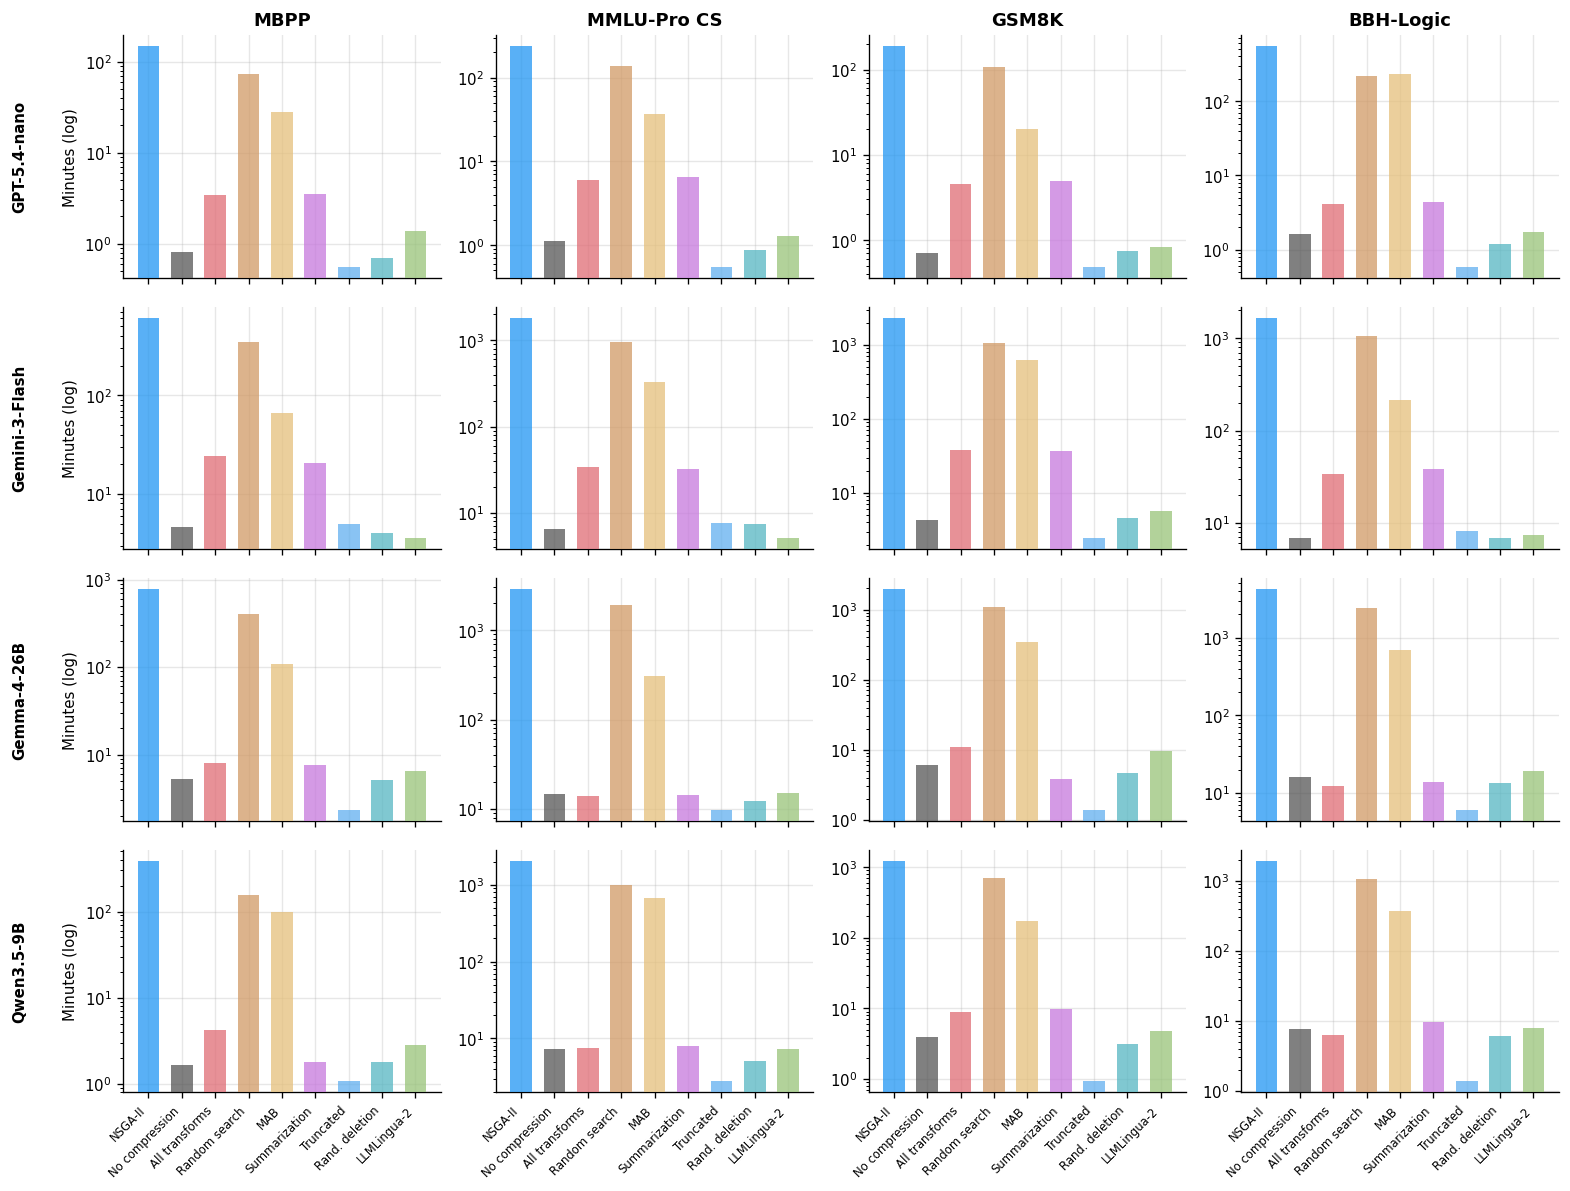

In [5]:
def collect_timing():
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            rows.append({
                'model': mlabel, 'task': tlabel,
                'approach': 'NSGA-II',
                'total_seconds': d['search_elapsed_seconds'] + d['eval_elapsed_seconds'],
            })
            for bl in d['baselines']:
                bname = bl['name']
                label = BASELINE_STYLE.get(bname, {}).get('label', bname)
                rows.append({
                    'model': mlabel, 'task': tlabel,
                    'approach': label,
                    'total_seconds': bl.get('elapsed_seconds', np.nan),
                })
    return pd.DataFrame(rows)


df_time = collect_timing()

if df_time.empty:
    print('No timing data available.')
else:
    df_time['total_minutes'] = df_time['total_seconds'] / 60

    approaches = (['NSGA-II']
                  + [st['label'] for st in BASELINE_STYLE.values()
                     if st['label'] in df_time['approach'].unique()])
    approaches = list(dict.fromkeys(approaches))

    app_colors = ([NSGA2_COLOR]
                  + [BASELINE_STYLE[k]['color']
                     for k in BASELINE_STYLE
                     if BASELINE_STYLE[k]['label'] in approaches[1:]])

    models_present = [lbl for lbl, _, _ in MODELS if lbl in df_time['model'].unique()]
    tasks_present  = [lbl for _, lbl, _ in TASKS
                      if lbl != 'MuSR' and lbl in df_time['task'].unique()]

    nrows = len(models_present)
    ncols = len(tasks_present)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL2, ROW_H * nrows),
                             squeeze=False, sharex='col')

    x = np.arange(len(approaches))
    width = 0.65

    for ri, mlabel in enumerate(models_present):
        for ci, tlabel in enumerate(tasks_present):
            ax = axes[ri][ci]
            sub = df_time[(df_time['model'] == mlabel) & (df_time['task'] == tlabel)]

            if ri == 0:
                ax.set_title(tlabel, fontweight='bold')
            if ci == 0:
                ax.annotate(mlabel, xy=(-0.35, 0.5), xycoords='axes fraction',
                            fontsize=9, fontweight='bold', rotation=90, va='center')
                ax.set_ylabel('Minutes (log)')

            if sub.empty:
                ax.text(0.5, 0.5, 'N/A', transform=ax.transAxes,
                        ha='center', va='center', color='gray')
                continue

            for pos, (appr, color) in enumerate(zip(approaches, app_colors)):
                val = sub[sub['approach'] == appr]['total_minutes'].dropna().values
                if len(val) == 0 or np.isnan(val[0]):
                    continue
                ax.bar(pos, val[0], width, color=color, alpha=0.75, zorder=3)

            ax.set_xticks(x)
            if ri == nrows - 1:
                ax.set_xticklabels(approaches, rotation=45, ha='right', fontsize=7)
            ax.set_yscale('log')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_1_timing.pdf', bbox_inches='tight')
    plt.show()

### RQ3.2 — Time distribution across models (per task)

Box plots showing how each approach's total time varies across models, aggregated per task.

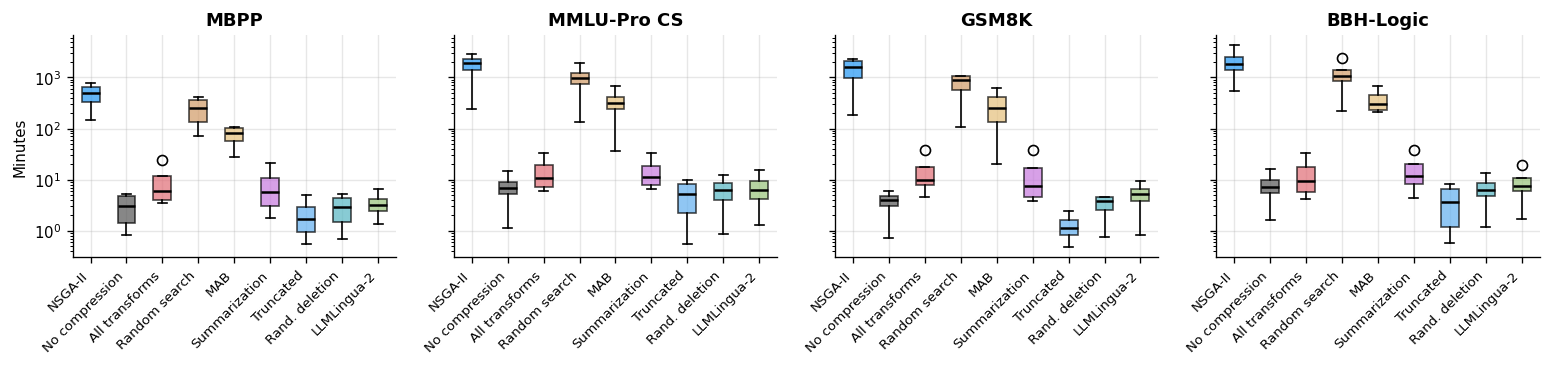

In [6]:
if df_time.empty:
    print('No timing data available.')
else:
    tasks_present  = [lbl for _, lbl, _ in TASKS
                      if lbl != 'MuSR' and lbl in df_time['task'].unique()]
    approaches_avail = list(dict.fromkeys(
        ['NSGA-II'] + [st['label'] for st in BASELINE_STYLE.values()
                        if st['label'] in df_time['approach'].unique()]))

    ncols = len(tasks_present)
    fig, axes = plt.subplots(1, ncols, figsize=(COL2, ROW_H * 1.25), squeeze=False, sharey=True)

    for ci, tlabel in enumerate(tasks_present):
        ax = axes[0][ci]
        sub = df_time[df_time['task'] == tlabel]
        data = [sub[sub['approach'] == a]['total_minutes'].dropna().values
                for a in approaches_avail]
        bp = ax.boxplot([d if len(d) else [np.nan] for d in data],
                        labels=approaches_avail, patch_artist=True,
                        medianprops=dict(color='black', lw=1.5))
        colors_bl = ([NSGA2_COLOR]
                     + [BASELINE_STYLE[k]['color']
                        for k in BASELINE_STYLE
                        if BASELINE_STYLE[k]['label'] in approaches_avail[1:]])
        for patch, color in zip(bp['boxes'], colors_bl[:len(bp['boxes'])]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(tlabel, fontweight='bold')
        ax.set_xticklabels(approaches_avail, rotation=45, ha='right', fontsize=8)
        ax.set_ylabel('Minutes' if ci == 0 else '')
        ax.set_yscale('log')

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_2_timing_boxplots.pdf', bbox_inches='tight')
    plt.show()

### RQ3.3 — Convergence: aggregated per task, averaged across models

Lines show the mean best performance and mean minimum tokens across models. Shaded regions show ±1 standard deviation.

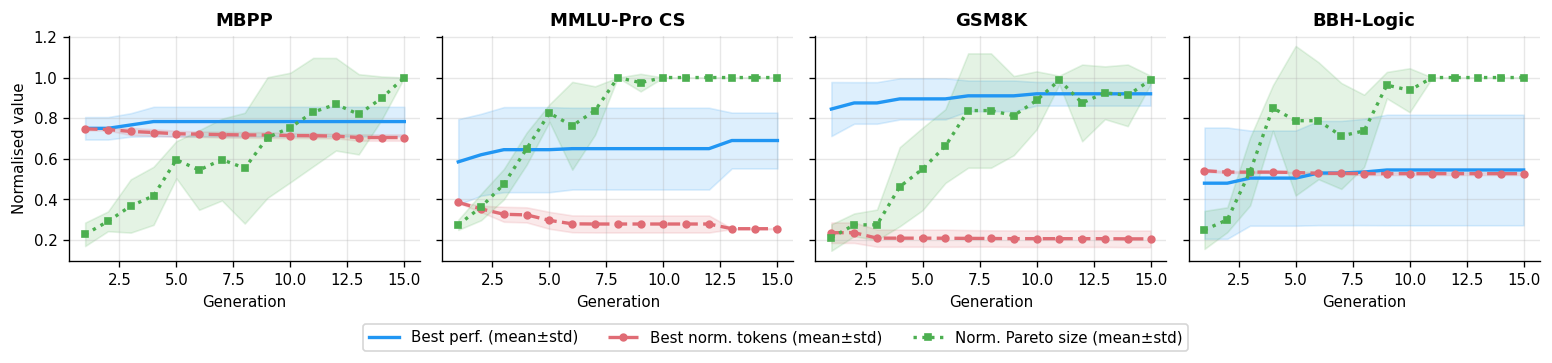

In [7]:
def collect_convergence():
    """Return dict task_label -> list of {model, history, no_compression_tokens}."""
    out = defaultdict(list)
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            history = d.get('generation_history', [])
            if not history:
                continue
            # No-compression token count for normalization
            ref = next((b for b in d['baselines'] if b['name'] == 'no_compression'), None)
            ref_tokens = (ref.get('test_avg_tokens') or ref.get('search_avg_tokens', 1)
                          if ref else 1)
            out[tlabel].append({'model': mlabel, 'history': history,
                                'ref_tokens': ref_tokens})
    return out


conv_data = collect_convergence()

if not conv_data:
    print('No generation history data available.')
else:
    tasks_conv = list(conv_data.keys())
    ncols = min(4, len(tasks_conv))
    nrows = (len(tasks_conv) + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, sharey=True,
                             figsize=(COL2, ROW_H * nrows * 1.1), squeeze=False)

    for idx, tlabel in enumerate(tasks_conv):
        ax = axes[idx // ncols][idx % ncols]
        entries = conv_data[tlabel]

        n_gens = max(h['history'][-1]['generation'] for h in entries)
        gens = list(range(1, n_gens + 1))

        all_best_perf   = []
        all_norm_tok    = []
        all_norm_pareto = []

        for entry in entries:
            gen_map = {h['generation']: h for h in entry['history']}
            ref_tok = max(entry['ref_tokens'], 1)
            max_n = max((gen_map[g]['n_solutions'] for g in gens if g in gen_map), default=1)
            max_n = max(max_n, 1)

            bp_series, nt_series, np_series = [], [], []
            for g in gens:
                h = gen_map.get(g)
                if h and h['pareto_front']:
                    bp_series.append(max(s['avg_performance'] for s in h['pareto_front']))
                    nt_series.append(min(s['avg_tokens'] for s in h['pareto_front']) / ref_tok)
                    np_series.append(h['n_solutions'] / max_n)
                else:
                    bp_series.append(np.nan)
                    nt_series.append(np.nan)
                    np_series.append(np.nan)
            all_best_perf.append(bp_series)
            all_norm_tok.append(nt_series)
            all_norm_pareto.append(np_series)

        def plot_mean_std(ax, gens, data, color, label, ls='-', marker=None):
            arr = np.array(data, dtype=float)
            mean = np.nanmean(arr, axis=0)
            std  = np.nanstd(arr, axis=0)
            ax.plot(gens, mean, color=color, lw=2, ls=ls, label=label,
                    marker=marker, markersize=4, markevery=max(1, len(gens)//10))
            ax.fill_between(gens, mean - std, mean + std, color=color, alpha=0.15)

        plot_mean_std(ax, gens, all_best_perf,  '#2196F3', 'Best perf. (mean±std)')
        plot_mean_std(ax, gens, all_norm_tok,   '#e06c75', 'Best norm. tokens (mean±std)',  ls='--', marker='o')
        plot_mean_std(ax, gens, all_norm_pareto,'#4caf50', 'Norm. Pareto size (mean±std)', ls=':', marker='s')

        ax.set_xlabel('Generation')
        if idx == 0:
            ax.set_ylabel('Normalised value')
        ax.set_title(tlabel, fontweight='bold')

    for idx in range(len(tasks_conv), nrows * ncols):
        axes[idx // ncols][idx % ncols].set_visible(False)

    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(labels),
               bbox_to_anchor=(0.5, -0.1), frameon=True, fontsize=9)
    plt.tight_layout()
    fig.savefig(FIG_DIR / 'rq3_3_convergence.pdf', bbox_inches='tight')
    plt.show()

---
## RQ4 — Patterns in Compression Strategies and Transferability

> *What patterns emerge in prompt compression strategies and how transferable are they across datasets?*

### RQ4.1 — Transferred Pareto fronts

Each subplot shows the native Pareto front (blue) alongside the transferred solutions from another task (orange). The grey diamond is the no-compression reference.

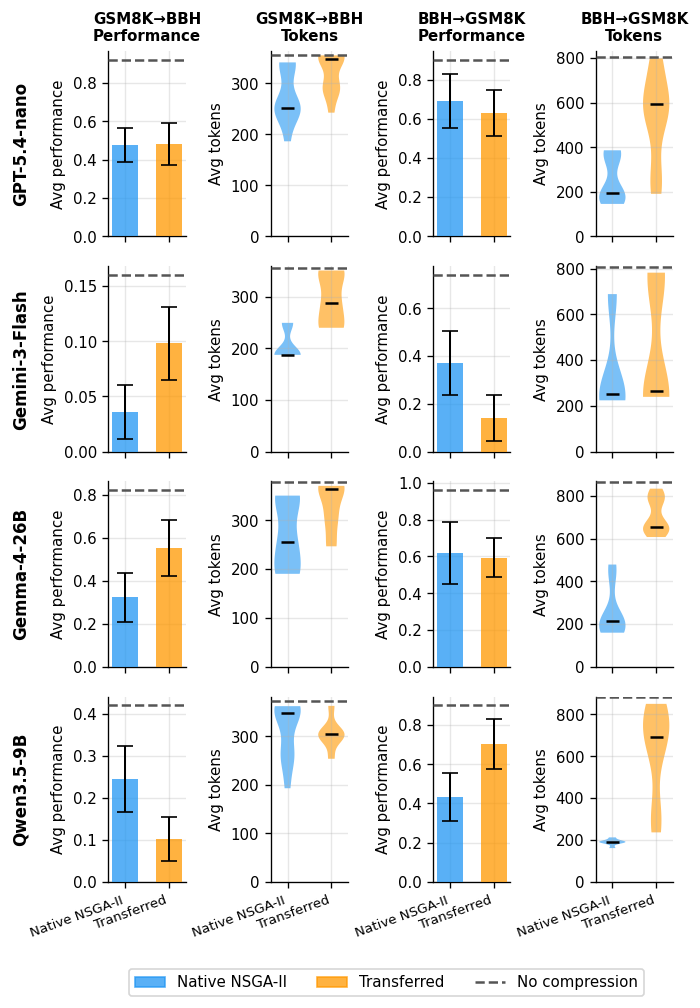

In [8]:
TASK_LABEL_MAP = {stem: lbl for stem, lbl, _ in TASKS}

def rq4_transfer_grid(filename=None):
    models_with_transfer = [
        (lbl, mdir) for lbl, mdir, _ in MODELS
        if any(f"transfer_{s}_to_{t}" in RESULTS[mdir] for s, t in TRANSFER_PAIRS)
    ]
    if not models_with_transfer:
        print("No transfer results available.")
        return

    pairs_avail = list(dict.fromkeys(
        (s, t) for s, t in TRANSFER_PAIRS
        for _, mdir in models_with_transfer
        if f"transfer_{s}_to_{t}" in RESULTS[mdir]
    ))

    nrows = len(models_with_transfer)
    # Each pair has 2 sub-columns: [perf bar, token dist]
    ncols = 2 * len(pairs_avail)
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(COL1, ROW_H * nrows * 0.8),
                             squeeze=False, sharex="all")

    bar_labels  = ["Native NSGA-II", "Transferred"]
    bar_colors  = [NSGA2_COLOR, "#FF9800"]
    x_positions = [0, 1]

    for ri, (mlabel, mdir) in enumerate(models_with_transfer):
        is_bottom_row = (ri == nrows - 1)
        for pi, (src, tgt) in enumerate(pairs_avail):
            src_lbl = TASK_LABEL_MAP.get(src, src)
            tgt_lbl = TASK_LABEL_MAP.get(tgt, tgt)
            col_perf = pi * 2
            col_tok  = pi * 2 + 1
            ax_perf  = axes[ri][col_perf]
            ax_tok   = axes[ri][col_tok]

            if ri == 0:
                ax_perf.set_title(f"{src_lbl}→{tgt_lbl}\nPerformance".replace("-Logic", ""), fontweight="bold", fontsize=9)
                ax_tok.set_title(f"{src_lbl}→{tgt_lbl}\nTokens".replace("-Logic", ""), fontweight="bold", fontsize=9)
            if pi == 0:
                ax_perf.annotate(mlabel, xy=(-1.25, 0.5), xycoords="axes fraction",
                                 fontsize=10, fontweight="bold", rotation=90, va="center")

            key = f"transfer_{src}_to_{tgt}"
            tr  = RESULTS[mdir].get(key)
            nat = RESULTS[mdir].get(tgt)

            if tr is None:
                for ax in (ax_perf, ax_tok):
                    ax.set_facecolor("#f5f5f5")
                    ax.text(0.5, 0.5, "N/A", transform=ax.transAxes,
                            ha="center", va="center", color="gray",
                            fontsize=11, fontstyle="italic")
                    ax.set_xticks(x_positions)
                    if is_bottom_row:
                        ax.set_xticklabels(bar_labels, rotation=20, ha="right", fontsize=8)
                ax_perf.set_ylabel("Avg performance")
                ax_perf.set_ylim(bottom=0)
                ax_tok.set_ylabel("Avg tokens")
                ax_tok.set_ylim(bottom=0)
                continue

            # Gather per-solution performance and token data
            nat_perfs = np.array([s.get("test_avg_performance") or s["search_avg_performance"]
                                  for s in nat["pareto_solutions"]]) if nat else np.array([])
            nat_toks  = np.array([s.get("test_avg_tokens") or s["search_avg_tokens"]
                                  for s in nat["pareto_solutions"]]) if nat else np.array([])
            tr_perfs  = np.array([s.get("test_avg_performance") or s["search_avg_performance"]
                                  for s in tr["solutions"]])
            tr_toks   = np.array([s.get("test_avg_tokens") or s["search_avg_tokens"]
                                  for s in tr["solutions"]])

            # No-compression reference
            nc_perf   = None
            nc_tokens = None
            if nat:
                ref = next((b for b in nat["baselines"] if b["name"] == "no_compression"), None)
                if ref:
                    nc_perf   = ref.get("test_avg_performance") or ref["search_avg_performance"]
                    nc_tokens = ref.get("test_avg_tokens")       or ref["search_avg_tokens"]

            # ── Left: performance bar chart with 95% CI ─────────────────────────────────
            for pos, (label, data) in zip(x_positions, zip(bar_labels, [nat_perfs, tr_perfs])):
                if len(data) == 0:
                    continue
                mean_val = np.mean(data)
                ci_val = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data)) if len(data) > 1 else 0
                ax_perf.bar(pos, mean_val, width=0.6, color=bar_colors[pos], alpha=0.75,
                            zorder=3)
                ax_perf.errorbar(pos, mean_val, yerr=ci_val, fmt="none",
                                 color="black", capsize=5, linewidth=1.2, zorder=4)

            if nc_perf is not None:
                ax_perf.axhline(nc_perf, color="#555555", lw=1.5, ls="--", zorder=5)

            ax_perf.set_xticks(x_positions)
            ax_perf.set_ylabel("Avg performance")
            ax_perf.set_ylim(bottom=0)
            if is_bottom_row:
                ax_perf.set_xticklabels(bar_labels, rotation=20, ha="right", fontsize=8)

            # ── Right: token distribution violin plot (positions match bar chart) ──
            tok_data      = [(d, c) for d, c in zip([nat_toks, tr_toks], bar_colors) if len(d) > 0]
            tok_positions = [p for p, d in zip(x_positions, [nat_toks, tr_toks]) if len(d) > 0]
            tok_x_labels  = [l for l, d in zip(bar_labels, [nat_toks, tr_toks]) if len(d) > 0]

            for pos, (data, color) in zip(tok_positions, tok_data):
                if len(data) < 2:
                    ax_tok.scatter([pos], [np.mean(data)], color=color, s=60,
                                   zorder=4, edgecolors="black", linewidths=0.8)
                    continue
                parts = ax_tok.violinplot([data], positions=[pos], widths=0.6,
                                          showmedians=True, showextrema=False)
                for pc in parts["bodies"]:
                    pc.set_facecolor(color)
                    pc.set_alpha(0.6)
                parts["cmedians"].set_color("black")
                parts["cmedians"].set_linewidth(1.5)

            if nc_tokens is not None:
                ax_tok.axhline(nc_tokens, color="#555555", lw=1.5, ls="--", zorder=5)

            ax_tok.set_xticks(x_positions)
            ax_tok.set_ylabel("Avg tokens")
            ax_tok.set_ylim(bottom=0)
            if is_bottom_row:
                ax_tok.set_xticklabels(tok_x_labels, rotation=20, ha="right", fontsize=8)

    # Shared legend
    legend_elements = [
        plt.Rectangle((0, 0), 1, 1, color=NSGA2_COLOR, alpha=0.75, label="Native NSGA-II"),
        plt.Rectangle((0, 0), 1, 1, color="#FF9800",   alpha=0.75, label="Transferred"),
        plt.Line2D([0], [0], color="#555555", lw=1.5, ls="--", label="No compression"),
    ]
    fig.legend(handles=legend_elements, loc="lower center", ncol=3,
               bbox_to_anchor=(0.6, -0.05), frameon=True, fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()


rq4_transfer_grid(filename="rq4_1_transfer.pdf")


### RQ4.2 — Operator usage in Pareto-optimal solutions

Bar chart showing average operator frequency in Pareto-optimal solutions across all models (excluding MuSR),
split by prompt section (`instruction` / `shots` — one subplot per section).
Operator names are taken from `transformation_names` (the correct field, derived directly from the
problem's operator list). Operators are sorted by decreasing overall mean frequency within each section.
The overlaid line with markers tracks the overall mean frequency across tasks.

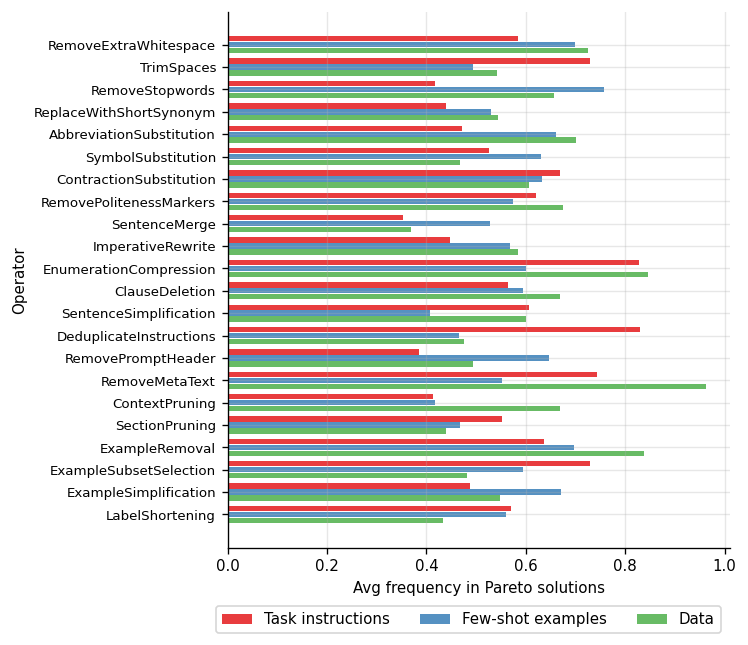

In [9]:
_SECTION_PREFIX = {'I': 'instruction', 'S': 'shots', 'D': 'data'}

# Canonical O1-O28 order (lexical -> syntactic -> structural -> semantic)
OP_ORDER = [
    'RemoveExtraWhitespace', 'TrimSpaces', 'RemoveStopwords', 'ReplaceWithShortSynonym',
    'AbbreviationSubstitution', 'SymbolSubstitution', 'ContractionSubstitution', 'RemovePolitenessMarkers',
    'SentenceMerge', 'ImperativeRewrite', 'EnumerationCompression', 'ClauseDeletion', 'SentenceSimplification',
    'DeduplicateInstructions', 'RemovePromptHeader', 'RemoveMetaText', 'ContextPruning', 'SectionPruning',
    'ExampleRemoval', 'ExampleSubsetSelection', 'ExampleSimplification', 'LabelShortening',
    'ContextCompression', 'InstructionSummarization', 'InstructionAbstraction', 'SchemaEncoding',
    'ExampleDistillation', 'ChunkCompression',
]


def collect_operator_usage():
    rows = []
    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, _ in TASKS:
            if tlabel == 'MuSR':
                continue
            d = RESULTS[mdir].get(stem)
            if d is None:
                continue
            sols = d['pareto_solutions']
            if not sols:
                continue

            op_section_counts = Counter()
            for sol in sols:
                for name in sol.get('transformation_names', []):
                    if ':' in name:
                        prefix, op_name = name.split(':', 1)
                        section = _SECTION_PREFIX.get(prefix, 'flat')
                    else:
                        op_name = name
                        section = 'flat'
                    op_section_counts[(op_name, section)] += 1

            for (op, section), cnt in op_section_counts.items():
                rows.append({
                    'model':     mlabel,
                    'task':      tlabel,
                    'operator':  op,
                    'section':   section,
                    'frequency': cnt / len(sols),
                })
    return pd.DataFrame(rows)


df_ops = collect_operator_usage()

if df_ops.empty:
    print('No operator usage data available.')
else:
    section_order    = ['instruction', 'shots', 'data', 'flat']
    sections_present = [s for s in section_order if s in df_ops['section'].unique()]

    section_colors = {s: c for s, c in zip(section_order, MODEL_COLORS)}

    # Average over models and tasks -> mean frequency per (operator, section)
    agg = df_ops.groupby(['operator', 'section'])['frequency'].mean().reset_index()

    # Operators in canonical O1-O28 order; append any unseen extras at the end
    ops_in_data = df_ops['operator'].unique().tolist()
    ops_ordered = [op for op in OP_ORDER if op in ops_in_data]
    ops_ordered += [op for op in ops_in_data if op not in OP_ORDER]

    pivot = (agg.pivot(index='operator', columns='section', values='frequency')
               .reindex(index=ops_ordered, columns=sections_present, fill_value=0))

    n_ops = len(ops_ordered)
    n_sec = len(sections_present)
    bar_h = 0.8 / n_sec

    fig, ax = plt.subplots(figsize=(COL1, ROW_H * 2))

    y_positions = np.arange(n_ops)

    section_labels = {
        'instruction': 'Task instructions',
        'shots':       'Few-shot examples',
        'data':        'Data',
        'flat':        'Flat',
    }

    for si, section in enumerate(sections_present):
        offset = (si - (n_sec - 1) / 2) * bar_h
        vals   = pivot[section].values
        ax.barh(y_positions + offset, vals, bar_h * 0.9,
                color=section_colors.get(section, '#888888'), alpha=0.85,
                label=section_labels.get(section, section))

    ax.set_yticks(y_positions)
    ax.set_yticklabels(ops_ordered, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel('Avg frequency in Pareto solutions')
    ax.set_ylabel('Operator')

    handles, leg_labels = ax.get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc='lower center', bbox_to_anchor=(0.625, -0.075),
               ncol=len(handles), fontsize=9, frameon=True)
    plt.tight_layout()
    fig.subplots_adjust(bottom=0.08)
    fig.savefig(FIG_DIR / 'rq4_2_operators.pdf', bbox_inches='tight')
    plt.show()

---
## Paper Numbers — Reproduction Script

Reproduces every specific number cited in the Results section of the paper (§Results, RQ1–RQ4).
All values are computed directly from the JSON result files; no rounding is applied in the computation,
only in the final `print` statements to match the precision used in the text.

In [10]:
# ── Shared helpers ────────────────────────────────────────────────────────────

def get_baseline(d, name):
    return next((b for b in d['baselines'] if b['name'] == name), None)

def bl_tok(b):
    return b.get('test_avg_tokens') or b['search_avg_tokens']

def bl_perf(b):
    return b.get('test_avg_performance') or b['search_avg_performance']

def sol_tok(s):
    return s.get('test_avg_tokens') or s['search_avg_tokens']

def sol_perf(s):
    return s.get('test_avg_performance') or s['search_avg_performance']

# map stem → label for quick lookup
STEM_TO_LABEL = {stem: lbl for stem, lbl, _ in TASKS}
LABEL_TO_STEM = {lbl: stem for stem, lbl, _ in TASKS}
MODEL_DIR     = {lbl: mdir for lbl, mdir, _ in MODELS}

print("Helpers ready.")

Helpers ready.


### RQ1 — Compression–Performance Trade-off

In [11]:
print("=" * 70)
print("RQ1 — per-model / per-task Pareto front statistics")
print("=" * 70)

for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        pareto = d['pareto_solutions']
        nc     = get_baseline(d, 'no_compression')
        if not pareto or nc is None:
            continue

        orig_tok  = bl_tok(nc)
        orig_perf = bl_perf(nc)

        # Extreme points on the Pareto front
        min_tok_sol  = min(pareto, key=sol_tok)
        max_perf_sol = max(pareto, key=sol_perf)

        min_tok       = sol_tok(min_tok_sol)
        max_reduction = (1 - min_tok / orig_tok) * 100
        max_perf      = sol_perf(max_perf_sol)
        tok_at_max    = sol_tok(max_perf_sol)

        # Best solution that matches or exceeds uncompressed accuracy (parity)
        parity_sols   = [s for s in pareto if sol_perf(s) >= orig_perf]
        if parity_sols:
            best_parity     = min(parity_sols, key=sol_tok)
            parity_tok      = sol_tok(best_parity)
            parity_reduction = (1 - parity_tok / orig_tok) * 100
            parity_str = (f"parity at {parity_tok:.0f} tok "
                          f"({parity_reduction:.1f}% reduction)")
        else:
            parity_str = "NO parity solution on Pareto front"

        # Performance improvement over baseline at the best-performance point
        perf_delta = max_perf - orig_perf

        print(f"\n  {mlabel} / {tlabel}")
        print(f"    Uncompressed baseline : {orig_perf:.2f} @ {orig_tok:.0f} tok")
        print(f"    Max compression       : {min_tok:.0f} tok  ({max_reduction:.1f}% reduction)")
        print(f"    Best Pareto perf      : {max_perf:.2f} @ {tok_at_max:.0f} tok  "
              f"(Δ = {perf_delta:+.2f} vs. baseline)")
        print(f"    Parity                : {parity_str}")

RQ1 — per-model / per-task Pareto front statistics

  GPT-5.4-nano / MBPP
    Uncompressed baseline : 0.76 @ 719 tok
    Max compression       : 541 tok  (24.8% reduction)
    Best Pareto perf      : 0.72 @ 584 tok  (Δ = -0.04 vs. baseline)
    Parity                : NO parity solution on Pareto front

  GPT-5.4-nano / MMLU-Pro CS
    Uncompressed baseline : 0.70 @ 330 tok
    Max compression       : 83 tok  (74.9% reduction)
    Best Pareto perf      : 0.76 @ 322 tok  (Δ = +0.06 vs. baseline)
    Parity                : parity at 282 tok (14.5% reduction)

  GPT-5.4-nano / GSM8K
    Uncompressed baseline : 0.90 @ 807 tok
    Max compression       : 146 tok  (82.0% reduction)
    Best Pareto perf      : 0.96 @ 386 tok  (Δ = +0.06 vs. baseline)
    Parity                : parity at 197 tok (75.6% reduction)

  GPT-5.4-nano / BBH-Logic
    Uncompressed baseline : 0.92 @ 356 tok
    Max compression       : 186 tok  (47.6% reduction)
    Best Pareto perf      : 0.74 @ 337 tok  (Δ = -0.18 

### RQ2 — Comparison with Baselines

In [12]:
print("=" * 70)
print("RQ2 — average performance and token count per method")
print("    (aggregated across all models × common tasks, excluding MuSR)")
print("=" * 70)

# Collect per-(model, task) summary: best-Pareto-perf solution + each baseline
bl_perf_lists = defaultdict(list)
bl_tok_lists  = defaultdict(list)

COMMON_STEMS = [stem for stem, _, lo in TASKS if not lo]

for mlabel, mdir, _ in MODELS:
    for stem in COMMON_STEMS:
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        pareto = d['pareto_solutions']

        # NSGA-II: best-compromise solution on the Pareto front
        if pareto:
            nc = get_baseline(d, "no_compression")
            ref_tokens = bl_tok(nc) if nc else 1.0

            best_id = find_best_pareto_id(pareto, ref_tokens)
            best = pareto[best_id]

            bl_perf_lists["NSGA-II (compromise)"].append(sol_perf(best))
            bl_tok_lists["NSGA-II (compromise)"].append(sol_tok(best))

        # Each named baseline
        for b in d['baselines']:
            bname = b['name']
            bl_perf_lists[bname].append(bl_perf(b))
            bl_tok_lists[bname].append(bl_tok(b))

# Display order
DISPLAY_ORDER = [
    ('NSGA-II (compromise)',    'NSGA-II (compromise)'),
    ('no_compression',   'No compression'),
    ('random_search',    'Random search'),
    ('multi_armed_bandit', 'Multi-Armed Bandit'),
    ('random_deletion',  'Random deletion'),
    ('llmlingua2',       'LLMLingua-2'),
    ('truncated_prompt', 'Truncated prompt'),
    ('summarization',    'Summarization'),
    ('all_transformations', 'All transformations'),
]

print(f"\n  {'Method':<35} {'Avg perf':>9}  {'Avg tokens':>10}  {'N':>4}")
print(f"  {'-'*35} {'-'*9}  {'-'*10}  {'-'*4}")
for key, label in DISPLAY_ORDER:
    perfs = bl_perf_lists.get(key, [])
    toks  = bl_tok_lists.get(key, [])
    if not perfs:
        continue
    avg_p = np.mean(perfs)
    avg_t = np.mean(toks)
    print(f"  {label:<35} {avg_p:>9.3f}  {avg_t:>10.0f}  {len(perfs):>4}")

# Average token reduction at parity for NSGA-II vs no-compression
nc_avg_tok   = np.mean(bl_tok_lists['no_compression'])
nsga_avg_tok = np.mean(bl_tok_lists['NSGA-II (compromise)'])
tok_reduction = (1 - nsga_avg_tok / nc_avg_tok) * 100
print(f"\n  Token reduction (NSGA-II best vs. no compression): {tok_reduction:.0f}%")
print(f"  ({nc_avg_tok:.0f} → {nsga_avg_tok:.0f} avg tokens)")

RQ2 — average performance and token count per method
    (aggregated across all models × common tasks, excluding MuSR)

  Method                               Avg perf  Avg tokens     N
  ----------------------------------- ---------  ----------  ----
  NSGA-II (compromise)                    0.634         354    16
  No compression                          0.671         581    16
  Random search                           0.409         352    16
  Multi-Armed Bandit                      0.483         384    16
  Random deletion                         0.380         390    16
  LLMLingua-2                             0.036         321    16
  Truncated prompt                        0.022         260    16
  Summarization                           0.019          50    16
  All transformations                     0.005          54    16

  Token reduction (NSGA-II best vs. no compression): 39%
  (581 → 354 avg tokens)


### RQ3 — Cost and Convergence

In [13]:
print("=" * 70)
print("RQ3.1 — Timing: total minutes per (model, task, approach)")
print("=" * 70)

timing_rows = []
for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        if tlabel == 'MuSR':
            continue
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        nsga2_min = (d['search_elapsed_seconds'] + d['eval_elapsed_seconds']) / 60
        timing_rows.append({'model': mlabel, 'task': tlabel,
                            'approach': 'NSGA-II', 'minutes': nsga2_min})
        for b in d['baselines']:
            bname = b['name']
            label = BASELINE_STYLE.get(bname, {}).get('label', bname)
            secs  = b.get('elapsed_seconds', np.nan)
            timing_rows.append({'model': mlabel, 'task': tlabel,
                                'approach': label, 'minutes': secs / 60})

df_timing = pd.DataFrame(timing_rows)

# Per-(model, task) detail for NSGA-II
print("\n  NSGA-II wall-clock time:")
nsga_times = df_timing[df_timing['approach'] == 'NSGA-II'].dropna(subset=['minutes'])
for _, row in nsga_times.sort_values('minutes').iterrows():
    h = row['minutes'] / 60
    print(f"    {row['model']:<18} / {row['task']:<14} : {row['minutes']:>7.1f} min  ({h:.1f} h)")

print(f"\n  Range: {nsga_times['minutes'].min():.0f} – {nsga_times['minutes'].max():.0f} min  "
      f"({nsga_times['minutes'].min()/60:.1f} – {nsga_times['minutes'].max()/60:.1f} h)")

# Ratio: NSGA-II vs Random Search and MAB per (model, task)
print("\n  NSGA-II / Random-Search and NSGA-II / MAB ratios:")
for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        if tlabel == 'MuSR':
            continue
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        nsga2_min = (d['search_elapsed_seconds'] + d['eval_elapsed_seconds']) / 60
        rs  = get_baseline(d, 'random_search')
        mab = get_baseline(d, 'multi_armed_bandit')
        rs_min  = rs.get('elapsed_seconds', np.nan) / 60  if rs  else np.nan
        mab_min = mab.get('elapsed_seconds', np.nan) / 60 if mab else np.nan
        rs_ratio  = nsga2_min / rs_min  if not np.isnan(rs_min)  and rs_min  > 0 else np.nan
        mab_ratio = nsga2_min / mab_min if not np.isnan(mab_min) and mab_min > 0 else np.nan
        print(f"    {mlabel:<18} / {tlabel:<14}: "
              f"NSGA2/RS={rs_ratio:.1f}×   NSGA2/MAB={mab_ratio:.1f}×")

RQ3.1 — Timing: total minutes per (model, task, approach)

  NSGA-II wall-clock time:
    GPT-5.4-nano       / MBPP           :   147.8 min  (2.5 h)
    GPT-5.4-nano       / GSM8K          :   186.8 min  (3.1 h)
    GPT-5.4-nano       / MMLU-Pro CS    :   235.7 min  (3.9 h)
    Qwen3.5-9B         / MBPP           :   391.0 min  (6.5 h)
    GPT-5.4-nano       / BBH-Logic      :   546.0 min  (9.1 h)
    Gemini-3-Flash     / MBPP           :   608.8 min  (10.1 h)
    Gemma-4-26B        / MBPP           :   775.7 min  (12.9 h)
    Qwen3.5-9B         / GSM8K          :  1236.4 min  (20.6 h)
    Gemini-3-Flash     / BBH-Logic      :  1662.5 min  (27.7 h)
    Gemini-3-Flash     / MMLU-Pro CS    :  1821.9 min  (30.4 h)
    Gemma-4-26B        / GSM8K          :  1950.1 min  (32.5 h)
    Qwen3.5-9B         / BBH-Logic      :  1954.2 min  (32.6 h)
    Qwen3.5-9B         / MMLU-Pro CS    :  2062.9 min  (34.4 h)
    Gemini-3-Flash     / GSM8K          :  2332.5 min  (38.9 h)
    Gemma-4-26B        

In [14]:
print("=" * 70)
print("RQ3.2 — Convergence: generation at which best-perf and min-token plateau")
print("=" * 70)

PLATEAU_THRESHOLD = 0.01   # change < 1% of range considered converged

for tlabel, entries in conv_data.items():
    print(f"\n  Task: {tlabel}")
    perf_plateaus = []
    tok_plateaus  = []

    for entry in entries:
        gen_map  = {h['generation']: h for h in entry['history']}
        ref_tok  = max(entry['ref_tokens'], 1)
        gens_all = sorted(gen_map.keys())

        best_perfs = []
        min_toks   = []
        for g in gens_all:
            h = gen_map[g]
            if h['pareto_front']:
                best_perfs.append(max(s['avg_performance'] for s in h['pareto_front']))
                min_toks.append(min(s['avg_tokens']       for s in h['pareto_front']) / ref_tok)
            else:
                best_perfs.append(np.nan)
                min_toks.append(np.nan)

        best_perfs = np.array(best_perfs)
        min_toks   = np.array(min_toks)

        # Find first generation where value stays within threshold of final value
        def plateau_gen(series, gens):
            final = series[~np.isnan(series)][-1]
            rng   = np.nanmax(series) - np.nanmin(series)
            thr   = PLATEAU_THRESHOLD * rng if rng > 0 else 0
            for i, (g, v) in enumerate(zip(gens, series)):
                if np.isnan(v):
                    continue
                if all(abs(series[j] - final) <= thr
                       for j in range(i, len(series)) if not np.isnan(series[j])):
                    return g
            return gens[-1]

        perf_plateaus.append(plateau_gen(best_perfs, gens_all))
        tok_plateaus.append(plateau_gen(min_toks,    gens_all))

    print(f"    Best-perf plateau generation  : "
          f"mean={np.mean(perf_plateaus):.1f}  range {min(perf_plateaus)}–{max(perf_plateaus)}")
    print(f"    Min-token plateau generation  : "
          f"mean={np.mean(tok_plateaus):.1f}  range {min(tok_plateaus)}–{max(tok_plateaus)}")

print(f"\n  (Plateau = first generation from which the value stays within "
      f"{PLATEAU_THRESHOLD*100:.0f}% of the final value)")

RQ3.2 — Convergence: generation at which best-perf and min-token plateau

  Task: MBPP
    Best-perf plateau generation  : mean=1.8  range 1–4
    Min-token plateau generation  : mean=10.8  range 7–13

  Task: MMLU-Pro CS
    Best-perf plateau generation  : mean=5.2  range 2–13
    Min-token plateau generation  : mean=8.0  range 6–13

  Task: GSM8K
    Best-perf plateau generation  : mean=4.8  range 1–10
    Min-token plateau generation  : mean=8.5  range 3–14

  Task: BBH-Logic
    Best-perf plateau generation  : mean=4.8  range 1–9
    Min-token plateau generation  : mean=7.0  range 5–8

  (Plateau = first generation from which the value stays within 1% of the final value)


### RQ4 — Operator Patterns and Transferability

In [15]:
print("=" * 70)
print("RQ4.1 — Transfer experiment: native vs. transferred Pareto solutions")
print("=" * 70)

for mlabel, mdir, _ in MODELS:
    printed_header = False
    for src_stem, tgt_stem in TRANSFER_PAIRS:
        key = f'transfer_{src_stem}_to_{tgt_stem}'
        tr  = RESULTS[mdir].get(key)
        nat = RESULTS[mdir].get(tgt_stem)
        if tr is None or nat is None:
            continue

        if not printed_header:
            print(f"\n  Model: {mlabel}")
            printed_header = True

        src_lbl = STEM_TO_LABEL.get(src_stem, src_stem)
        tgt_lbl = STEM_TO_LABEL.get(tgt_stem, tgt_stem)

        nat_perfs = [sol_perf(s) for s in nat['pareto_solutions']]
        nat_toks  = [sol_tok(s)  for s in nat['pareto_solutions']]
        tr_perfs  = [sol_perf(s) for s in tr['solutions']]
        tr_toks   = [sol_tok(s)  for s in tr['solutions']]

        nat_avg_p = np.mean(nat_perfs)
        nat_avg_t = np.mean(nat_toks)
        tr_avg_p  = np.mean(tr_perfs)
        tr_avg_t  = np.mean(tr_toks)

        # Performance retention = transferred_perf / native_perf
        perf_retention = tr_avg_p / nat_avg_p * 100 if nat_avg_p > 0 else np.nan
        tok_ratio      = tr_avg_t / nat_avg_t

        print(f"    {src_lbl} → {tgt_lbl}")
        print(f"      Native NSGA-II : perf={nat_avg_p:.3f}  tok={nat_avg_t:.0f}")
        print(f"      Transferred    : perf={tr_avg_p:.3f}  tok={tr_avg_t:.0f}")
        print(f"      Retention      : perf={perf_retention:.0f}%   "
              f"tok ratio={tok_ratio:.2f}×  "
              f"({'MORE' if tok_ratio > 1 else 'FEWER'} tokens than native)")

RQ4.1 — Transfer experiment: native vs. transferred Pareto solutions

  Model: GPT-5.4-nano
    GSM8K → BBH-Logic
      Native NSGA-II : perf=0.478  tok=275
      Transferred    : perf=0.482  tok=319
      Retention      : perf=101%   tok ratio=1.16×  (MORE tokens than native)
    BBH-Logic → GSM8K
      Native NSGA-II : perf=0.690  tok=253
      Transferred    : perf=0.629  tok=536
      Retention      : perf=91%   tok ratio=2.11×  (MORE tokens than native)

  Model: Gemini-3-Flash
    GSM8K → BBH-Logic
      Native NSGA-II : perf=0.036  tok=206
      Transferred    : perf=0.098  tok=295
      Retention      : perf=272%   tok ratio=1.43×  (MORE tokens than native)
    BBH-Logic → GSM8K
      Native NSGA-II : perf=0.372  tok=354
      Transferred    : perf=0.139  tok=454
      Retention      : perf=37%   tok ratio=1.28×  (MORE tokens than native)

  Model: Gemma-4-26B
    GSM8K → BBH-Logic
      Native NSGA-II : perf=0.322  tok=271
      Transferred    : perf=0.551  tok=329
      Reten

In [16]:
print("=" * 70)
print("RQ4.2 — Operator usage: mean frequency in Pareto solutions per section")
print("=" * 70)

_SECTION_PREFIX = {'I': 'instruction', 'S': 'shots', 'D': 'data'}

# Build DataFrame of (model, task, operator, section, frequency) — same as df_ops above
op_rows = []
for mlabel, mdir, _ in MODELS:
    for stem, tlabel, _ in TASKS:
        if tlabel == 'MuSR':
            continue
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue
        sols = d['pareto_solutions']
        if not sols:
            continue
        op_section_counts = Counter()
        for sol in sols:
            for name in sol.get('transformation_names', []):
                if ':' in name:
                    prefix, op_name = name.split(':', 1)
                    section = _SECTION_PREFIX.get(prefix, 'flat')
                else:
                    op_name, section = name, 'flat'
                op_section_counts[(op_name, section)] += 1
        for (op, section), cnt in op_section_counts.items():
            op_rows.append({'model': mlabel, 'task': tlabel,
                            'operator': op, 'section': section,
                            'frequency': cnt / len(sols)})

df_op = pd.DataFrame(op_rows)

for section in ['instruction', 'shots', 'data']:
    sub = df_op[df_op['section'] == section]
    if sub.empty:
        continue
    overall_mean = sub.groupby('operator')['frequency'].mean().sort_values(ascending=False)
    top10 = overall_mean.head(10)
    bottom3 = overall_mean.tail(3)

    print(f"\n  Section: {section}")
    print(f"    Overall mean freq. range: {overall_mean.min():.3f} – {overall_mean.max():.3f}")
    print(f"    Top operators (overall mean freq.):")
    for op, freq in top10.items():
        # per-task breakdown
        per_task = sub[sub['operator'] == op].groupby('task')['frequency'].mean()
        task_str = "  ".join(f"{t}={v:.2f}" for t, v in per_task.items())
        print(f"      {op:<30}  mean={freq:.3f}   [{task_str}]")
    print(f"    Bottom operators:")
    for op, freq in bottom3.items():
        print(f"      {op:<30}  mean={freq:.3f}")

RQ4.2 — Operator usage: mean frequency in Pareto solutions per section

  Section: instruction
    Overall mean freq. range: 0.352 – 0.830
    Top operators (overall mean freq.):
      DeduplicateInstructions         mean=0.830   [BBH-Logic=0.85  GSM8K=0.96  MBPP=0.59  MMLU-Pro CS=0.93]
      EnumerationCompression          mean=0.828   [BBH-Logic=0.90  GSM8K=0.73  MBPP=0.76  MMLU-Pro CS=0.90]
      RemoveMetaText                  mean=0.743   [BBH-Logic=0.75  GSM8K=0.65  MBPP=0.76  MMLU-Pro CS=0.83]
      TrimSpaces                      mean=0.730   [BBH-Logic=0.67  GSM8K=0.81  MBPP=0.93  MMLU-Pro CS=0.50]
      ExampleSubsetSelection          mean=0.729   [BBH-Logic=0.78  GSM8K=0.60  MBPP=0.77  MMLU-Pro CS=0.78]
      ContractionSubstitution         mean=0.670   [BBH-Logic=0.57  GSM8K=0.93  MBPP=0.36  MMLU-Pro CS=0.66]
      ExampleRemoval                  mean=0.636   [BBH-Logic=0.47  GSM8K=0.95  MBPP=0.72  MMLU-Pro CS=0.53]
      RemovePolitenessMarkers         mean=0.620   [BBH-Lo

## Statistical tests

| RQ                                             |                                                       Metric | Recommended aggregate test                                                                                                                  | Unit of pairing                                        | Effect size / CI to report                                   |
| ---------------------------------------------- | -----------------------------------------------------------: | ------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------ | ------------------------------------------------------------ |
| **RQ1: compression–performance trade-off**     |                                Token count / token reduction | **Wilcoxon signed-rank test** on per-instance token counts; aggregate also across 16 model×benchmark cells                                  | Same test prompt before/after compression              | Median token reduction %, Hodges–Lehmann CI                  |
|                                                |                             Accuracy / Exact Match / pass\@1 | **Exact McNemar test** when output is binary correct/incorrect                                                                              | Same test item under compressed vs uncompressed prompt | Δ accuracy / Δ EM / Δ pass\@1 with 95% paired bootstrap CI   |
|                                                |                     If using BLEU or other continuous metric | **Paired bootstrap** or **paired permutation test**                                                                                         | Same test item                                         | Mean/median Δ metric with 95% CI                             |
| **RQ2: comparison with baselines**             |                                             Task performance | **Friedman test** across methods over the 16 model×benchmark cells; post-hoc **Wilcoxon signed-rank** vs each baseline with Holm correction | Each model×benchmark cell                              | Median Δ performance; Cliff’s δ or rank-biserial correlation |
|                                                |                                                  Token count | Same as above: Friedman + post-hoc Wilcoxon                                                                                                 | Each model×benchmark cell                              | Median Δ tokens / Δ compression                              |
|                                                |                                              Joint trade-off | **Wilcoxon signed-rank** on scalarized score or hypervolume contribution                                                                    | Each model×benchmark cell                              | Δ hypervolume or Δ normalized utility                        |
| **RQ3: cost and convergence**                  |    Number of LLM calls / unique evaluations / cache hit rate | **Wilcoxon signed-rank** vs Random Search and MAB                                                                                           | Each model×benchmark cell                              | Median Δ calls, Δ cache-hit rate                             |
|                                                |     Final hypervolume / best-so-far utility after budget 300 | **Wilcoxon signed-rank** vs Random Search and MAB                                                                                           | Each model×benchmark cell                              | Δ hypervolume with 95% bootstrap CI                          |
|                                                |                                            Convergence trend | Prefer descriptive: area under convergence curve, generation of 95% final HV; optional Wilcoxon over cells                                  | Each model×benchmark cell                              | Median generation-to-threshold                               |
| **RQ4: operator patterns and transferability** |                                               Operator usage | **Exact binomial / χ² goodness-of-fit** at category level, not per operator, to save space                                                  | Selected strategy per model×benchmark cell             | Usage frequency by category                                  |
|                                                | Operator-category distribution: lexical/syntactic/structural | **χ² goodness-of-fit** or Fisher exact if counts are small                                                                                  | Operator selections pooled over 16 cells               | Cramér’s V                                                   |
|                                                |                                         Transfer performance | Same as RQ1: McNemar for binary metrics; paired bootstrap for continuous metrics                                                            | Same target test item, native vs transferred strategy  | Δ performance CI                                             |
|                                                |                                         Transfer token count | Wilcoxon signed-rank                                                                                                                        | Same target test prompt                                | Median Δ tokens                                              |


### RQ1 - Token reduction + task-performance preservation

Use:

* **Wilcoxon signed-rank** for token reduction;
* **Exact McNemar** for binary task metrics: Accuracy, Exact Match, pass\@1;
* **paired bootstrap CI** where metrics are continuous or corpus-level.

In [21]:
# ============================================================================
# RQ1 — Statistical tests for compression-performance trade-off
#   - Token count: paired Wilcoxon signed-rank test
#   - Binary task performance: exact McNemar test
#   - Continuous/non-binary performance: paired bootstrap CI
# ============================================================================

from scipy.stats import wilcoxon, binomtest
import numpy as np
import pandas as pd

RNG = np.random.default_rng(42)
N_BOOT = 10_000

def _safe_metric_value(row, key):
    v = row.get(key, np.nan)
    try:
        return float(v)
    except Exception:
        return np.nan

def _is_binary_array(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    return len(x) > 0 and np.all(np.isin(x, [0.0, 1.0]))

def paired_bootstrap_ci(x, y, stat_fn=lambda a, b: np.mean(a - b), n_boot=N_BOOT, seed=42):
    """Bootstrap CI for paired difference stat_fn(x, y)."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x, y = x[mask], y[mask]
    if len(x) == 0:
        return np.nan, np.nan, np.nan

    obs = stat_fn(x, y)
    boots = []
    n = len(x)
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boots.append(stat_fn(x[idx], y[idx]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return obs, lo, hi

def exact_mcnemar_p(a, b):
    """
    Exact McNemar test for paired binary correctness.
    a, b: arrays with 0/1 correctness for method A and B.
    Returns p-value and discordant counts.
    """
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = ~(np.isnan(a) | np.isnan(b))
    a, b = a[mask], b[mask]

    b01 = int(np.sum((a == 1) & (b == 0)))  # A correct, B wrong
    b10 = int(np.sum((a == 0) & (b == 1)))  # A wrong, B correct
    n_discordant = b01 + b10

    if n_discordant == 0:
        return 1.0, b01, b10

    p = binomtest(min(b01, b10), n=n_discordant, p=0.5, alternative="two-sided").pvalue
    return p, b01, b10

def _row_key(row, fallback_idx):
    """
    Robust sample identifier. If detailed JSONL has an explicit id, use it.
    Otherwise fall back to row order within each solution.
    """
    for k in ["sample_id", "instance_id", "doc_id", "prompt_id", "example_id", "idx", "index"]:
        if k in row:
            return row[k]
    return fallback_idx

def collect_solution_rows(det, solution_type, solution_id=None):
    rows = []
    counter = 0
    for row in det:
        if row.get("solution_type") != solution_type:
            continue
        if solution_id is not None and row.get("solution_id") != solution_id:
            continue
        rows.append({
            "key": _row_key(row, counter),
            "performance": _safe_metric_value(row, "performance"),
            "tokens": _safe_metric_value(row, "compressed_tokens"),
        })
        counter += 1
    return pd.DataFrame(rows)

def collect_baseline_rows(det, baseline_name):
    return collect_solution_rows(det, f"baseline_{baseline_name}")

def best_compromise_id_for_run(d):
    nc = get_baseline(d, "no_compression")
    ref_tokens = bl_tok(nc) if nc else 1.0
    return find_best_pareto_id(d["pareto_solutions"], ref_tokens)

rq1_rows = []

for mlabel, mdir, _ in MODELS:
    for stem, tlabel, local_only in TASKS:
        if local_only:
            continue

        d = RESULTS[mdir].get(stem)
        det = DETAILED[mdir].get(stem)
        if d is None or det is None:
            continue

        best_id = best_compromise_id_for_run(d)

        df_nsga = collect_solution_rows(det, "pareto", solution_id=best_id)
        df_nc   = collect_baseline_rows(det, "no_compression")

        paired = df_nsga.merge(df_nc, on="key", suffixes=("_nsga", "_nc"))
        if paired.empty:
            print(f"[RQ1] No paired rows for {mlabel} / {tlabel}")
            continue

        # Token reduction: paired Wilcoxon on token counts
        tok_nsga = paired["tokens_nsga"].to_numpy(dtype=float)
        tok_nc   = paired["tokens_nc"].to_numpy(dtype=float)
        tok_mask = ~(np.isnan(tok_nsga) | np.isnan(tok_nc))
        tok_nsga, tok_nc = tok_nsga[tok_mask], tok_nc[tok_mask]

        if len(tok_nsga) > 0 and np.any(tok_nsga != tok_nc):
            w_tok = wilcoxon(tok_nsga, tok_nc, alternative="less", zero_method="wilcox")
            tok_p = w_tok.pvalue
        else:
            tok_p = 1.0

        tok_delta, tok_ci_lo, tok_ci_hi = paired_bootstrap_ci(
            tok_nc, tok_nsga,
            stat_fn=lambda a, b: np.median(a - b),
            seed=42
        )

        # Performance: McNemar if binary, otherwise paired bootstrap
        perf_nsga = paired["performance_nsga"].to_numpy(dtype=float)
        perf_nc   = paired["performance_nc"].to_numpy(dtype=float)

        if _is_binary_array(perf_nsga) and _is_binary_array(perf_nc):
            perf_p, nc_correct_nsga_wrong, nc_wrong_nsga_correct = exact_mcnemar_p(perf_nc, perf_nsga)
            perf_test = "exact McNemar"
            perf_delta = np.nanmean(perf_nsga) - np.nanmean(perf_nc)
            perf_ci_lo, perf_ci_hi = paired_bootstrap_ci(
                perf_nsga, perf_nc,
                stat_fn=lambda a, b: np.mean(a - b),
                seed=43
            )[1:]
        else:
            perf_delta, perf_ci_lo, perf_ci_hi = paired_bootstrap_ci(
                perf_nsga, perf_nc,
                stat_fn=lambda a, b: np.mean(a - b),
                seed=43
            )
            perf_p = np.nan
            perf_test = "paired bootstrap CI"
            nc_correct_nsga_wrong = np.nan
            nc_wrong_nsga_correct = np.nan

        rq1_rows.append({
            "model": mlabel,
            "task": tlabel,
            "n_pairs": len(paired),
            "nsga_perf": np.nanmean(perf_nsga),
            "no_comp_perf": np.nanmean(perf_nc),
            "delta_perf": perf_delta,
            "delta_perf_ci95": f"[{perf_ci_lo:.4f}, {perf_ci_hi:.4f}]",
            "perf_test": perf_test,
            "perf_p": perf_p,
            "nc_correct_nsga_wrong": nc_correct_nsga_wrong,
            "nc_wrong_nsga_correct": nc_wrong_nsga_correct,
            "nsga_tokens": np.nanmean(tok_nsga) if len(tok_nsga) else np.nan,
            "no_comp_tokens": np.nanmean(tok_nc) if len(tok_nc) else np.nan,
            "median_token_saving": tok_delta,
            "median_token_saving_ci95": f"[{tok_ci_lo:.2f}, {tok_ci_hi:.2f}]",
            "token_wilcoxon_p": tok_p,
            "token_reduction_pct": 100 * (1 - np.nanmean(tok_nsga) / np.nanmean(tok_nc)) if len(tok_nsga) else np.nan,
        })

df_rq1_stats = pd.DataFrame(rq1_rows)
display(df_rq1_stats)

df_rq1_stats.to_csv(FIG_DIR / "rq1_statistical_tests.csv", index=False)
print(f"Saved: {FIG_DIR / 'rq1_statistical_tests.csv'}")

,model,task,n_pairs,nsga_perf,no_comp_perf,delta_perf,delta_perf_ci95,perf_test,perf_p,nc_correct_nsga_wrong,nc_wrong_nsga_correct,nsga_tokens,no_comp_tokens,median_token_saving,median_token_saving_ci95,token_wilcoxon_p,token_reduction_pct
0,GPT-5.4-nano,MBPP,50,0.72,0.72,0.00,"[-0.0800, 0.0800]",exact McNemar,1.000000e+00,2,2,584.26,719.26,135.0,"[135.00, 135.00]",7.687299e-13,18.769291
1,GPT-5.4-nano,MMLU-Pro CS,50,0.54,0.74,-0.20,"[-0.3400, -0.0600]",exact McNemar,1.293945e-02,12,2,254.88,329.84,72.0,"[56.50, 80.00]",3.762263e-10,22.726170
2,GPT-5.4-nano,GSM8K,50,0.92,0.90,0.02,"[0.0000, 0.0600]",exact McNemar,1.000000e+00,0,1,324.32,807.30,482.0,"[482.00, 483.00]",1.663776e-10,59.826582
3,GPT-5.4-nano,BBH-Logic,50,0.48,0.96,-0.48,"[-0.6200, -0.3400]",exact McNemar,8.046627e-07,25,1,250.42,355.90,95.0,"[92.00, 115.00]",3.697240e-10,29.637539
4,Gemini-3-Flash,MBPP,50,0.64,0.62,0.02,"[-0.1200, 0.1600]",exact McNemar,1.000000e+00,6,7,562.30,719.26,156.0,"[155.00, 157.00]",3.591380e-10,21.822429
5,Gemini-3-Flash,MMLU-Pro CS,50,0.46,0.32,0.14,"[0.0000, 0.2800]",exact McNemar,9.228516e-02,3,10,280.76,329.84,49.0,"[49.00, 49.00]",1.671550e-10,14.879942
6,Gemini-3-Flash,GSM8K,50,0.66,0.76,-0.10,"[-0.2200, 0.0200]",exact McNemar,1.796875e-01,7,2,274.32,807.30,532.0,"[532.00, 533.00]",1.663776e-10,66.020067
7,Gemini-3-Flash,BBH-Logic,50,0.12,0.24,-0.12,"[-0.2600, 0.0200]",exact McNemar,1.795654e-01,10,4,249.42,355.90,96.0,"[93.00, 116.00]",3.697240e-10,29.918516
8,Gemma-4-26B,MBPP,50,0.56,0.66,-0.10,"[-0.2400, 0.0400]",exact McNemar,2.668457e-01,9,4,691.18,858.94,167.0,"[166.00, 168.00]",3.570213e-10,19.531050
9,Gemma-4-26B,MMLU-Pro CS,50,0.80,0.80,0.00,"[-0.1000, 0.1000]",exact McNemar,1.000000e+00,3,3,305.06,353.52,49.0,"[48.00, 49.00]",1.825621e-10,13.707852


Saved: ../paper/prompt_piper_paper/figures/rq1_statistical_tests.csv


### RQ2 - Aggregate baseline comparison across model×benchmark cells

Use one aggregate test over the 16 configurations:

* **Friedman test** across methods for task performance;
* **Friedman test** across methods for token count;
* **post-hoc Wilcoxon signed-rank** comparing NSGA-II with each baseline;
* **Holm correction** for multiple baselines.

In [22]:
# ============================================================================
# RQ2 — Aggregate comparison with baselines
#   - Friedman test across methods over model × task cells
#   - Holm-corrected Wilcoxon signed-rank tests: NSGA-II vs each baseline
#   - Metrics: performance, tokens, and optional scalar utility
# ============================================================================

from scipy.stats import friedmanchisquare, wilcoxon, rankdata
import numpy as np
import pandas as pd

def holm_correction(pvals):
    """
    Holm-Bonferroni correction.
    Returns adjusted p-values in original order.
    """
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m, dtype=float)

    running_max = 0.0
    for rank, idx in enumerate(order):
        corrected = (m - rank) * pvals[idx]
        running_max = max(running_max, corrected)
        adj[idx] = min(running_max, 1.0)
    return adj

def rank_biserial_effect_size_paired(x, y):
    """
    Rank-biserial correlation for paired differences x - y.
    Positive means x > y.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = ~(np.isnan(x) | np.isnan(y))
    d = x[mask] - y[mask]
    d = d[d != 0]
    if len(d) == 0:
        return 0.0

    ranks = rankdata(np.abs(d))
    w_pos = np.sum(ranks[d > 0])
    w_neg = np.sum(ranks[d < 0])
    return (w_pos - w_neg) / np.sum(ranks)

def compromise_solution_summary(d):
    best_id = best_compromise_id_for_run(d)
    s = d["pareto_solutions"][best_id]
    return {
        "method": "NSGA-II",
        "performance": sol_perf(s),
        "tokens": sol_tok(s),
    }

rq2_cells = []

COMMON_STEMS = [(stem, label) for stem, label, local_only in TASKS if not local_only]

for mlabel, mdir, _ in MODELS:
    for stem, tlabel in COMMON_STEMS:
        d = RESULTS[mdir].get(stem)
        if d is None:
            continue

        nc = get_baseline(d, "no_compression")
        if nc is None:
            continue
        ref_tokens = bl_tok(nc)

        # NSGA-II compromise solution
        nsga = compromise_solution_summary(d)
        rq2_cells.append({
            "cell": f"{mlabel}::{tlabel}",
            "model": mlabel,
            "task": tlabel,
            "method": "NSGA-II",
            "performance": nsga["performance"],
            "tokens": nsga["tokens"],
            "compression": 1 - nsga["tokens"] / ref_tokens,
            "utility": nsga["performance"] + (1 - nsga["tokens"] / ref_tokens),
        })

        # Baselines
        for b in d["baselines"]:
            bname = b["name"]
            label = BASELINE_STYLE.get(bname, {}).get("label", bname)
            perf = bl_perf(b)
            tok = bl_tok(b)
            rq2_cells.append({
                "cell": f"{mlabel}::{tlabel}",
                "model": mlabel,
                "task": tlabel,
                "method": label,
                "performance": perf,
                "tokens": tok,
                "compression": 1 - tok / ref_tokens,
                "utility": perf + (1 - tok / ref_tokens),
            })

df_rq2_cells = pd.DataFrame(rq2_cells)

def rq2_friedman_and_posthoc(df, metric, higher_is_better=True):
    """
    Aggregate test across model × benchmark cells.
    """
    wide = df.pivot_table(index="cell", columns="method", values=metric, aggfunc="mean")

    # Keep only methods available in all cells
    wide = wide.dropna(axis=1)
    if "NSGA-II" not in wide.columns:
        raise ValueError("NSGA-II column missing after pivot/dropna.")

    # Friedman across all complete methods
    arrays = [wide[col].to_numpy(dtype=float) for col in wide.columns]
    fried_stat, fried_p = friedmanchisquare(*arrays)

    # Post-hoc Wilcoxon: NSGA-II vs each baseline
    posthoc_rows = []
    nsga = wide["NSGA-II"].to_numpy(dtype=float)

    pvals = []
    tmp = []

    for method in wide.columns:
        if method == "NSGA-II":
            continue

        other = wide[method].to_numpy(dtype=float)

        # Directional alternative:
        # performance/compression/utility: NSGA-II greater
        # tokens: NSGA-II less
        if higher_is_better:
            alternative = "greater"
        else:
            alternative = "less"

        if np.allclose(nsga, other, equal_nan=True):
            p = 1.0
        else:
            p = wilcoxon(nsga, other, alternative=alternative, zero_method="wilcox").pvalue

        pvals.append(p)
        tmp.append({
            "metric": metric,
            "baseline": method,
            "n_cells": len(wide),
            "nsga_median": np.nanmedian(nsga),
            "baseline_median": np.nanmedian(other),
            "median_delta_nsga_minus_baseline": np.nanmedian(nsga - other),
            "rank_biserial_r": rank_biserial_effect_size_paired(nsga, other),
            "p_raw": p,
        })

    p_adj = holm_correction(pvals) if pvals else []
    for row, adj in zip(tmp, p_adj):
        row["p_holm"] = adj
        posthoc_rows.append(row)

    return {
        "metric": metric,
        "friedman_stat": fried_stat,
        "friedman_p": fried_p,
        "methods": list(wide.columns),
        "n_cells": len(wide),
        "wide": wide,
        "posthoc": pd.DataFrame(posthoc_rows),
    }

rq2_results = []
rq2_posthoc = []

for metric, higher in [
    ("performance", True),
    ("tokens", False),
    ("compression", True),
    ("utility", True),
]:
    res = rq2_friedman_and_posthoc(df_rq2_cells, metric, higher_is_better=higher)
    rq2_results.append({
        "metric": metric,
        "n_cells": res["n_cells"],
        "n_methods": len(res["methods"]),
        "friedman_stat": res["friedman_stat"],
        "friedman_p": res["friedman_p"],
        "methods": ", ".join(res["methods"]),
    })
    rq2_posthoc.append(res["posthoc"])

df_rq2_friedman = pd.DataFrame(rq2_results)
df_rq2_posthoc = pd.concat(rq2_posthoc, ignore_index=True)

display(df_rq2_friedman)
display(df_rq2_posthoc.sort_values(["metric", "p_holm"]))

df_rq2_friedman.to_csv(FIG_DIR / "rq2_friedman_tests.csv", index=False)
df_rq2_posthoc.to_csv(FIG_DIR / "rq2_holm_wilcoxon_posthoc.csv", index=False)

print(f"Saved: {FIG_DIR / 'rq2_friedman_tests.csv'}")
print(f"Saved: {FIG_DIR / 'rq2_holm_wilcoxon_posthoc.csv'}")

,metric,n_cells,n_methods,friedman_stat,friedman_p,methods
0,performance,16,9,114.561920,4.385425e-21,"All transforms, LLMLingua-2, MAB, NSGA-II, No ..."
1,tokens,16,9,102.066667,1.613191e-18,"All transforms, LLMLingua-2, MAB, NSGA-II, No ..."
2,compression,16,9,102.066667,1.613191e-18,"All transforms, LLMLingua-2, MAB, NSGA-II, No ..."
3,utility,16,9,65.750000,3.429350e-11,"All transforms, LLMLingua-2, MAB, NSGA-II, No ..."


,metric,baseline,n_cells,nsga_median,baseline_median,median_delta_nsga_minus_baseline,rank_biserial_r,p_raw,p_holm
19,compression,No compression,16,0.222743,0.000000,0.222743,1.000000,0.000015,0.000122
16,compression,All transforms,16,0.222743,0.915987,-0.638974,-1.000000,1.000000,1.000000
17,compression,LLMLingua-2,16,0.222743,0.468797,-0.205635,-0.455882,0.947708,1.000000
18,compression,MAB,16,0.222743,0.221148,-0.000695,0.250000,0.201874,1.000000
20,compression,Rand. deletion,16,0.222743,0.332832,-0.086480,-0.147059,0.701706,1.000000
21,compression,Random search,16,0.222743,0.322673,-0.009842,-0.264706,0.825806,1.000000
22,compression,Summarization,16,0.222743,0.912680,-0.635892,-1.000000,1.000000,1.000000
23,compression,Truncated,16,0.222743,0.551661,-0.353270,-0.808824,0.998932,1.000000
5,performance,Random search,16,0.650000,0.425556,0.255000,0.955882,0.000076,0.000610
0,performance,All transforms,16,0.650000,0.000000,0.640000,1.000000,0.000218,0.001522


Saved: ../paper/prompt_piper_paper/figures/rq2_friedman_tests.csv
Saved: ../paper/prompt_piper_paper/figures/rq2_holm_wilcoxon_posthoc.csv


### RQ3 - Cost, final search quality, and convergence descriptors

Use:

* final hypervolume or normalized best-compromise utility: **Wilcoxon signed-rank** NSGA-II vs Random Search/MAB;
* LLM calls or cache savings: **Wilcoxon signed-rank**;
* convergence: report **descriptive curves**, plus median generation reaching 95% of final hypervolume.

In [23]:
# ============================================================================
# RQ3 — Cost and convergence characteristics
#   - Cost: Wilcoxon signed-rank test over model × task cells
#   - Search quality: normalized 2D hypervolume over performance/compression
#   - Convergence: descriptive only, no generation-level inferential test
# ============================================================================

from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

def pareto_hypervolume_2d(points):
    """
    Hypervolume for maximization points in [0, 1]^2 with reference point (0, 0).
    Points are (x=compression, y=performance).
    """
    pts = np.asarray(points, dtype=float)
    if pts.size == 0:
        return np.nan

    pts = pts[~np.isnan(pts).any(axis=1)]
    pts = np.clip(pts, 0, 1)
    if len(pts) == 0:
        return np.nan

    # Non-dominated filtering for maximization
    nd = []
    for p in pts:
        dominated = False
        for q in pts:
            if np.all(q >= p) and np.any(q > p):
                dominated = True
                break
        if not dominated:
            nd.append(tuple(p))

    nd = np.array(sorted(set(nd), key=lambda z: z[0]))
    if len(nd) == 0:
        return np.nan

    hv = 0.0
    prev_x = 0.0
    best_y_from_right = 0.0

    # Sort by compression ascending; integrate upper envelope
    for x, y in nd:
        if y > best_y_from_right:
            hv += max(0, x - prev_x) * y
            prev_x = x
            best_y_from_right = y

    # Simpler robust envelope integration
    nd = nd[np.argsort(nd[:, 0])]
    hv = 0.0
    prev_x = 0.0
    current_y = 0.0
    for x, y in nd:
        if y > current_y:
            hv += (x - prev_x) * current_y
            prev_x = x
            current_y = y
    hv += (1.0 - prev_x) * current_y
    return hv

def nsga_test_hv(d):
    nc = get_baseline(d, "no_compression")
    if nc is None:
        return np.nan
    ref_tokens = bl_tok(nc)
    points = []
    for s in d.get("pareto_solutions", []):
        perf = sol_perf(s)
        comp = 1 - sol_tok(s) / ref_tokens
        points.append([comp, perf])
    return pareto_hypervolume_2d(points)

def single_solution_hv(d, bname):
    """
    Baseline as a one-point trade-off. Useful for Random Search / MAB summaries
    if only one aggregate baseline point is stored.
    """
    nc = get_baseline(d, "no_compression")
    b = get_baseline(d, bname)
    if nc is None or b is None:
        return np.nan
    ref_tokens = bl_tok(nc)
    comp = 1 - bl_tok(b) / ref_tokens
    perf = bl_perf(b)
    return pareto_hypervolume_2d([[comp, perf]])

def generation_hv_series(d):
    """
    Search-set HV per generation using generation_history.
    """
    nc = get_baseline(d, "no_compression")
    if nc is None:
        return []
    ref_tokens = bl_tok(nc)
    out = []

    for h in d.get("generation_history", []):
        points = []
        for s in h.get("pareto_front", []):
            perf = s.get("avg_performance", np.nan)
            tok = s.get("avg_tokens", np.nan)
            comp = 1 - tok / ref_tokens
            points.append([comp, perf])
        out.append({
            "generation": h.get("generation"),
            "hv": pareto_hypervolume_2d(points),
            "n_solutions": h.get("n_solutions", np.nan),
        })
    return out

def first_generation_reaching_fraction(series, fraction=0.95):
    """
    First generation reaching fraction of final HV.
    """
    df = pd.DataFrame(series).dropna(subset=["generation", "hv"])
    if df.empty:
        return np.nan
    final_hv = df.sort_values("generation")["hv"].iloc[-1]
    if final_hv <= 0 or np.isnan(final_hv):
        return np.nan
    target = fraction * final_hv
    reached = df[df["hv"] >= target]
    if reached.empty:
        return np.nan
    return int(reached.sort_values("generation")["generation"].iloc[0])

rq3_rows = []

for mlabel, mdir, _ in MODELS:
    for stem, tlabel, local_only in TASKS:
        if local_only:
            continue

        d = RESULTS[mdir].get(stem)
        if d is None:
            continue

        nsga_minutes = (d.get("search_elapsed_seconds", np.nan) + d.get("eval_elapsed_seconds", np.nan)) / 60
        nsga_hv = nsga_test_hv(d)
        gen_series = generation_hv_series(d)

        row = {
            "cell": f"{mlabel}::{tlabel}",
            "model": mlabel,
            "task": tlabel,
            "nsga_minutes": nsga_minutes,
            "nsga_hv": nsga_hv,
            "gen_95pct_final_hv": first_generation_reaching_fraction(gen_series, fraction=0.95),
            "final_pareto_size": len(d.get("pareto_solutions", [])),
        }

        for bname in ["random_search", "multi_armed_bandit"]:
            b = get_baseline(d, bname)
            label = BASELINE_STYLE.get(bname, {}).get("label", bname)
            if b is not None:
                row[f"{label}_minutes"] = b.get("elapsed_seconds", np.nan) / 60
                row[f"{label}_hv"] = single_solution_hv(d, bname)

        rq3_rows.append(row)

df_rq3 = pd.DataFrame(rq3_rows)
display(df_rq3)

# Paired Wilcoxon tests vs Random Search and MAB
rq3_test_rows = []

for label in ["Random search", "MAB"]:
    for metric, higher in [
        ("minutes", False),
        ("hv", True),
    ]:
        nsga_col = f"nsga_{metric}"
        other_col = f"{label}_{metric}"

        if other_col not in df_rq3.columns:
            continue

        sub = df_rq3[[nsga_col, other_col]].dropna()
        if sub.empty:
            continue

        x = sub[nsga_col].to_numpy(dtype=float)
        y = sub[other_col].to_numpy(dtype=float)

        if np.allclose(x, y):
            p = 1.0
        else:
            alt = "less" if not higher else "greater"
            p = wilcoxon(x, y, alternative=alt, zero_method="wilcox").pvalue

        rq3_test_rows.append({
            "comparison": f"NSGA-II vs {label}",
            "metric": metric,
            "n_cells": len(sub),
            "nsga_median": np.median(x),
            f"{label}_median": np.median(y),
            "median_delta_nsga_minus_other": np.median(x - y),
            "wilcoxon_p": p,
            "alternative": "NSGA-II smaller" if not higher else "NSGA-II larger",
        })

df_rq3_tests = pd.DataFrame(rq3_test_rows)

# Convergence descriptors
df_rq3_conv = (
    df_rq3
    .groupby("task", as_index=False)
    .agg(
        n_cells=("cell", "count"),
        median_gen_95pct_final_hv=("gen_95pct_final_hv", "median"),
        min_gen_95pct_final_hv=("gen_95pct_final_hv", "min"),
        max_gen_95pct_final_hv=("gen_95pct_final_hv", "max"),
        median_final_pareto_size=("final_pareto_size", "median"),
    )
)

display(df_rq3_tests)
display(df_rq3_conv)

df_rq3.to_csv(FIG_DIR / "rq3_cost_hv_cells.csv", index=False)
df_rq3_tests.to_csv(FIG_DIR / "rq3_wilcoxon_cost_hv_tests.csv", index=False)
df_rq3_conv.to_csv(FIG_DIR / "rq3_convergence_descriptors.csv", index=False)

print(f"Saved: {FIG_DIR / 'rq3_cost_hv_cells.csv'}")
print(f"Saved: {FIG_DIR / 'rq3_wilcoxon_cost_hv_tests.csv'}")
print(f"Saved: {FIG_DIR / 'rq3_convergence_descriptors.csv'}")

,cell,model,task,nsga_minutes,nsga_hv,gen_95pct_final_hv,final_pareto_size,Random search_minutes,Random search_hv,MAB_minutes,MAB_hv
0,GPT-5.4-nano::MBPP,GPT-5.4-nano,MBPP,147.808749,0.584861,1,20,72.785366,0.276306,28.146146,0.467522
1,GPT-5.4-nano::MMLU-Pro CS,GPT-5.4-nano,MMLU-Pro CS,235.703427,0.742581,1,20,137.131059,0.238772,36.795029,0.342397
2,GPT-5.4-nano::GSM8K,GPT-5.4-nano,GSM8K,186.848799,0.459368,4,20,108.266519,0.179015,19.918441,0.131546
3,GPT-5.4-nano::BBH-Logic,GPT-5.4-nano,BBH-Logic,545.979060,0.701035,1,20,219.167059,0.341481,233.813566,0.590231
4,Gemini-3-Flash::MBPP,Gemini-3-Flash,MBPP,608.793242,0.562879,4,20,344.113450,0.449801,65.501245,0.300066
5,Gemini-3-Flash::MMLU-Pro CS,Gemini-3-Flash,MMLU-Pro CS,1821.921339,0.391552,13,20,965.017326,0.175852,328.106573,0.188849
6,Gemini-3-Flash::GSM8K,Gemini-3-Flash,GSM8K,2332.489614,0.265275,4,20,1052.639829,0.185227,632.683090,0.239037
7,Gemini-3-Flash::BBH-Logic,Gemini-3-Flash,BBH-Logic,1662.496812,0.084098,3,20,1053.830571,0.047071,211.528438,0.130006
8,Gemma-4-26B::MBPP,Gemma-4-26B,MBPP,775.721289,0.450626,1,20,406.508281,0.282217,107.679708,0.291309
9,Gemma-4-26B::MMLU-Pro CS,Gemma-4-26B,MMLU-Pro CS,2870.822210,0.690337,3,20,1900.097836,0.321441,305.529051,0.502337


,comparison,metric,n_cells,nsga_median,Random search_median,median_delta_nsga_minus_other,wilcoxon_p,alternative,MAB_median
0,NSGA-II vs Random search,minutes,16,1449.441828,835.064702,569.970503,1.000000,NSGA-II smaller,NaN
1,NSGA-II vs Random search,hv,16,0.497497,0.235122,0.248027,0.000015,NSGA-II larger,NaN
2,NSGA-II vs MAB,minutes,16,1449.441828,NaN,1222.585501,1.000000,NSGA-II smaller,222.671002
3,NSGA-II vs MAB,hv,16,0.497497,NaN,0.173659,0.000839,NSGA-II larger,0.333328


,task,n_cells,median_gen_95pct_final_hv,min_gen_95pct_final_hv,max_gen_95pct_final_hv,median_final_pareto_size
0,BBH-Logic,4,2.0,1,8,20.0
1,GSM8K,4,3.0,1,4,20.0
2,MBPP,4,1.0,1,4,20.0
3,MMLU-Pro CS,4,2.5,1,13,20.0


Saved: ../paper/prompt_piper_paper/figures/rq3_cost_hv_cells.csv
Saved: ../paper/prompt_piper_paper/figures/rq3_wilcoxon_cost_hv_tests.csv
Saved: ../paper/prompt_piper_paper/figures/rq3_convergence_descriptors.csv


### RQ4 - Operator-pattern tests + transferability tests

For operator patterns:

* aggregate operators into your existing categories: Lexical, Syntactic, Structural;
* test whether category usage is non-uniform using **χ² goodness-of-fit** or Fisher/exact multinomial test;
* report category frequencies and Cramér’s V.

For transferability:

* use **McNemar** for binary task metrics;
* **Wilcoxon** for token counts;
* compare native PromptPiper strategy vs transferred strategy on the same target test items.

In [24]:
# ============================================================================
# RQ4 — Operator patterns and transferability
#   - Operator categories: chi-square goodness-of-fit over Lexical/Syntactic/Structural
#   - Transferability:
#       * tokens: paired Wilcoxon
#       * binary performance: exact McNemar
#       * non-binary performance: paired bootstrap CI
# ============================================================================

from scipy.stats import chisquare, wilcoxon
import numpy as np
import pandas as pd
from collections import Counter

# O1-O22 only, because search excludes semantic operators in your setup.
OP_CATEGORY = {
    # Lexical O1-O8
    "RemoveExtraWhitespace": "Lexical",
    "TrimSpaces": "Lexical",
    "RemoveStopwords": "Lexical",
    "ReplaceWithShortSynonym": "Lexical",
    "AbbreviationSubstitution": "Lexical",
    "SymbolSubstitution": "Lexical",
    "ContractionSubstitution": "Lexical",
    "RemovePolitenessMarkers": "Lexical",

    # Syntactic O9-O13
    "SentenceMerge": "Syntactic",
    "ImperativeRewrite": "Syntactic",
    "EnumerationCompression": "Syntactic",
    "ClauseDeletion": "Syntactic",
    "SentenceSimplification": "Syntactic",

    # Structural O14-O22
    "DeduplicateInstructions": "Structural",
    "RemovePromptHeader": "Structural",
    "RemoveMetaText": "Structural",
    "ContextPruning": "Structural",
    "SectionPruning": "Structural",
    "ExampleRemoval": "Structural",
    "ExampleSubsetSelection": "Structural",
    "ExampleSimplification": "Structural",
    "LabelShortening": "Structural",
}

def strip_section_prefix(transformation_name):
    if ":" in transformation_name:
        return transformation_name.split(":", 1)[1]
    return transformation_name

def category_usage_counts():
    rows = []

    for mlabel, mdir, _ in MODELS:
        for stem, tlabel, local_only in TASKS:
            if local_only:
                continue

            d = RESULTS[mdir].get(stem)
            if d is None:
                continue

            counts = Counter()
            total = 0

            for sol in d.get("pareto_solutions", []):
                for tr in sol.get("transformation_names", []):
                    op = strip_section_prefix(tr)
                    cat = OP_CATEGORY.get(op)
                    if cat is not None:
                        counts[cat] += 1
                        total += 1

            for cat in ["Lexical", "Syntactic", "Structural"]:
                rows.append({
                    "model": mlabel,
                    "task": tlabel,
                    "category": cat,
                    "count": counts[cat],
                    "total": total,
                    "proportion": counts[cat] / total if total > 0 else np.nan,
                })

    return pd.DataFrame(rows)

df_rq4_cat = category_usage_counts()
display(df_rq4_cat)

# Aggregate category-level chi-square against uniform usage.
# If you prefer expected counts proportional to number of operators per category,
# replace expected with counts based on category sizes.
agg_counts = (
    df_rq4_cat
    .groupby("category", as_index=True)["count"]
    .sum()
    .reindex(["Lexical", "Syntactic", "Structural"])
)

observed = agg_counts.to_numpy(dtype=float)
expected_uniform = np.repeat(observed.sum() / len(observed), len(observed))

chi_stat, chi_p = chisquare(f_obs=observed, f_exp=expected_uniform)
cramers_v = np.sqrt(chi_stat / (observed.sum() * (len(observed) - 1))) if observed.sum() > 0 else np.nan

df_rq4_operator_test = pd.DataFrame([{
    "test": "chi-square goodness-of-fit",
    "null": "uniform category usage",
    "categories": ", ".join(agg_counts.index),
    "observed_counts": ", ".join(str(int(x)) for x in observed),
    "chi2": chi_stat,
    "p": chi_p,
    "cramers_v": cramers_v,
}])

display(df_rq4_operator_test)

# Optional: per-task category tests
per_task_rows = []
for tlabel, sub in df_rq4_cat.groupby("task"):
    counts = sub.groupby("category")["count"].sum().reindex(["Lexical", "Syntactic", "Structural"]).fillna(0)
    obs = counts.to_numpy(dtype=float)
    if obs.sum() == 0:
        continue
    exp = np.repeat(obs.sum() / len(obs), len(obs))
    stat, p = chisquare(f_obs=obs, f_exp=exp)
    v = np.sqrt(stat / (obs.sum() * (len(obs) - 1)))
    per_task_rows.append({
        "task": tlabel,
        "observed_counts": ", ".join(str(int(x)) for x in obs),
        "chi2": stat,
        "p": p,
        "cramers_v": v,
    })

df_rq4_operator_by_task = pd.DataFrame(per_task_rows)
display(df_rq4_operator_by_task)

# ---------------------------------------------------------------------------
# Transferability tests
# ---------------------------------------------------------------------------

def best_compromise_id_for_transfer_result(tr):
    """
    Select best transferred solution by normalized distance to ideal point.
    Transfer result has 'solutions', not 'pareto_solutions'.
    """
    sols = tr.get("solutions", [])
    if not sols:
        return None

    max_tok = max([sol_tok(s) for s in sols] + [1])
    best_id, best_dist = None, float("inf")

    for i, s in enumerate(sols):
        perf = sol_perf(s)
        tok = sol_tok(s)
        dist = np.sqrt((1 - perf) ** 2 + (tok / max_tok) ** 2)
        if dist < best_dist:
            best_dist, best_id = dist, i

    return best_id

rq4_transfer_rows = []

for mlabel, mdir, _ in MODELS:
    for src_stem, tgt_stem in TRANSFER_PAIRS:
        key = f"transfer_{src_stem}_to_{tgt_stem}"

        tr = RESULTS[mdir].get(key)
        nat = RESULTS[mdir].get(tgt_stem)

        det_tr = DETAILED[mdir].get(key)
        det_nat = DETAILED[mdir].get(tgt_stem)

        if tr is None or nat is None or det_tr is None or det_nat is None:
            continue

        native_id = best_compromise_id_for_run(nat)
        transfer_id = best_compromise_id_for_transfer_result(tr)

        if native_id is None or transfer_id is None:
            continue

        df_native = collect_solution_rows(det_nat, "pareto", solution_id=native_id)

        # Transfer detailed files may use solution_type == "transfer" or "pareto".
        # Try the common possibilities and keep the first non-empty result.
        candidate_transfer_dfs = [
            collect_solution_rows(det_tr, "transfer", solution_id=transfer_id),
            collect_solution_rows(det_tr, "pareto", solution_id=transfer_id),
        ]
        df_transfer = next((x for x in candidate_transfer_dfs if not x.empty), pd.DataFrame())

        if df_transfer.empty:
            # Fallback: any rows with matching solution_id regardless of solution_type
            tmp = []
            counter = 0
            for row in det_tr:
                if row.get("solution_id") == transfer_id:
                    tmp.append({
                        "key": _row_key(row, counter),
                        "performance": _safe_metric_value(row, "performance"),
                        "tokens": _safe_metric_value(row, "compressed_tokens"),
                    })
                    counter += 1
            df_transfer = pd.DataFrame(tmp)

        paired = df_native.merge(df_transfer, on="key", suffixes=("_native", "_transfer"))

        if paired.empty:
            print(f"[RQ4 transfer] No paired rows for {mlabel}: {src_stem} -> {tgt_stem}")
            continue

        perf_native = paired["performance_native"].to_numpy(dtype=float)
        perf_transfer = paired["performance_transfer"].to_numpy(dtype=float)
        tok_native = paired["tokens_native"].to_numpy(dtype=float)
        tok_transfer = paired["tokens_transfer"].to_numpy(dtype=float)

        # Token comparison: transferred vs native.
        tok_mask = ~(np.isnan(tok_native) | np.isnan(tok_transfer))
        if tok_mask.sum() > 0 and np.any(tok_transfer[tok_mask] != tok_native[tok_mask]):
            tok_p = wilcoxon(
                tok_transfer[tok_mask],
                tok_native[tok_mask],
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue
        else:
            tok_p = 1.0

        median_tok_delta = np.nanmedian(tok_transfer - tok_native)

        # Performance comparison
        if _is_binary_array(perf_native) and _is_binary_array(perf_transfer):
            perf_p, native_correct_transfer_wrong, native_wrong_transfer_correct = exact_mcnemar_p(
                perf_native,
                perf_transfer
            )
            perf_test = "exact McNemar"
            perf_delta = np.nanmean(perf_transfer) - np.nanmean(perf_native)
            perf_ci_lo, perf_ci_hi = paired_bootstrap_ci(
                perf_transfer,
                perf_native,
                stat_fn=lambda a, b: np.mean(a - b),
                seed=44
            )[1:]
        else:
            perf_delta, perf_ci_lo, perf_ci_hi = paired_bootstrap_ci(
                perf_transfer,
                perf_native,
                stat_fn=lambda a, b: np.mean(a - b),
                seed=44
            )
            perf_p = np.nan
            perf_test = "paired bootstrap CI"
            native_correct_transfer_wrong = np.nan
            native_wrong_transfer_correct = np.nan

        rq4_transfer_rows.append({
            "model": mlabel,
            "source_task": STEM_TO_LABEL.get(src_stem, src_stem),
            "target_task": STEM_TO_LABEL.get(tgt_stem, tgt_stem),
            "n_pairs": len(paired),
            "native_perf": np.nanmean(perf_native),
            "transfer_perf": np.nanmean(perf_transfer),
            "delta_perf_transfer_minus_native": perf_delta,
            "delta_perf_ci95": f"[{perf_ci_lo:.4f}, {perf_ci_hi:.4f}]",
            "perf_test": perf_test,
            "perf_p": perf_p,
            "native_correct_transfer_wrong": native_correct_transfer_wrong,
            "native_wrong_transfer_correct": native_wrong_transfer_correct,
            "native_tokens": np.nanmean(tok_native),
            "transfer_tokens": np.nanmean(tok_transfer),
            "median_token_delta_transfer_minus_native": median_tok_delta,
            "token_wilcoxon_p": tok_p,
        })

df_rq4_transfer_tests = pd.DataFrame(rq4_transfer_rows)
display(df_rq4_transfer_tests)

df_rq4_cat.to_csv(FIG_DIR / "rq4_operator_category_counts.csv", index=False)
df_rq4_operator_test.to_csv(FIG_DIR / "rq4_operator_category_chisquare.csv", index=False)
df_rq4_operator_by_task.to_csv(FIG_DIR / "rq4_operator_category_chisquare_by_task.csv", index=False)
df_rq4_transfer_tests.to_csv(FIG_DIR / "rq4_transferability_tests.csv", index=False)

print(f"Saved: {FIG_DIR / 'rq4_operator_category_counts.csv'}")
print(f"Saved: {FIG_DIR / 'rq4_operator_category_chisquare.csv'}")
print(f"Saved: {FIG_DIR / 'rq4_operator_category_chisquare_by_task.csv'}")
print(f"Saved: {FIG_DIR / 'rq4_transferability_tests.csv'}")

,model,task,category,count,total,proportion
0,GPT-5.4-nano,MBPP,Lexical,258,763,0.338139
1,GPT-5.4-nano,MBPP,Syntactic,171,763,0.224115
2,GPT-5.4-nano,MBPP,Structural,334,763,0.437746
3,GPT-5.4-nano,MMLU-Pro CS,Lexical,228,629,0.362480
4,GPT-5.4-nano,MMLU-Pro CS,Syntactic,147,629,0.233704
5,GPT-5.4-nano,MMLU-Pro CS,Structural,254,629,0.403816
6,GPT-5.4-nano,GSM8K,Lexical,237,643,0.368585
7,GPT-5.4-nano,GSM8K,Syntactic,154,643,0.239502
8,GPT-5.4-nano,GSM8K,Structural,252,643,0.391913
9,GPT-5.4-nano,BBH-Logic,Lexical,261,698,0.373926


,test,null,categories,observed_counts,chi2,p,cramers_v
0,chi-square goodness-of-fit,uniform category usage,"Lexical, Syntactic, Structural","3983, 2396, 4419",629.856825,1.691719e-137,0.170779


,task,observed_counts,chi2,p,cramers_v
0,BBH-Logic,"958, 653, 1106",117.827751,2.594352e-26,0.147253
1,GSM8K,"990, 511, 1107",229.427147,1.515402e-50,0.209727
2,MBPP,"1134, 691, 1148",136.324924,2.497002e-30,0.151417
3,MMLU-Pro CS,"901, 541, 1058",168.615200,2.430382e-37,0.183638


,model,source_task,target_task,n_pairs,native_perf,transfer_perf,delta_perf_transfer_minus_native,delta_perf_ci95,perf_test,perf_p,native_correct_transfer_wrong,native_wrong_transfer_correct,native_tokens,transfer_tokens,median_token_delta_transfer_minus_native,token_wilcoxon_p
0,GPT-5.4-nano,GSM8K,BBH-Logic,50,0.48,0.42,-0.06,"[-0.1800, 0.0600]",exact McNemar,0.507812,6,3,250.42,252.42,2.0,1.537460e-12
1,GPT-5.4-nano,BBH-Logic,GSM8K,50,0.92,0.94,0.02,"[0.0000, 0.0600]",exact McNemar,1.000000,0,1,324.32,198.08,-127.0,1.279727e-10
2,Gemini-3-Flash,GSM8K,BBH-Logic,50,0.12,0.12,0.00,"[-0.0800, 0.0800]",exact McNemar,1.000000,2,2,249.42,250.42,1.0,1.537460e-12
3,Gemini-3-Flash,BBH-Logic,GSM8K,50,0.66,0.32,-0.34,"[-0.5000, -0.1800]",exact McNemar,0.000488,20,3,274.32,249.82,-21.5,7.321077e-10
4,Gemma-4-26B,GSM8K,BBH-Logic,50,0.34,0.26,-0.08,"[-0.1800, 0.0000]",exact McNemar,0.218750,5,1,256.52,270.52,14.0,1.537460e-12
5,Gemma-4-26B,BBH-Logic,GSM8K,50,0.96,0.86,-0.10,"[-0.2000, -0.0200]",exact McNemar,0.062500,5,0,217.70,406.70,189.0,1.537460e-12
6,Qwen3.5-9B,GSM8K,BBH-Logic,50,0.48,0.36,-0.12,"[-0.2600, 0.0200]",exact McNemar,0.179565,10,4,359.74,362.74,3.0,1.537460e-12
7,Qwen3.5-9B,BBH-Logic,GSM8K,50,0.94,0.50,-0.44,"[-0.6000, -0.2800]",exact McNemar,0.000010,24,2,212.64,843.30,631.0,1.411817e-10


Saved: ../paper/prompt_piper_paper/figures/rq4_operator_category_counts.csv
Saved: ../paper/prompt_piper_paper/figures/rq4_operator_category_chisquare.csv
Saved: ../paper/prompt_piper_paper/figures/rq4_operator_category_chisquare_by_task.csv
Saved: ../paper/prompt_piper_paper/figures/rq4_transferability_tests.csv
